In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import pymannkendall as mk

# --- 1. 文件路径和变量设置 ---
input_file = r"C:\Users\11823\era5land\202209202402\albedo_filter202209G.nc"
csv_output_file = r"C:\Users\11823\era5land\202209202402\albedo_MK_Trend.csv"

variable_name = 'albedo' 
time_dim_name = 'time' 
trend_factor = 10 # 趋势乘以 10 得到每十年变化量
alpha = 0.05      # 95% 置信度

# --- 2. Mann-Kendall (MK) 核心函数 ---

def mann_kendall_test(data):
    """
    对一维时间序列数据执行 Mann-Kendall 和 Sen's Slope 测试。
    """
    # 移除 NaN 值
    data_clean = data[~np.isnan(data)]

    # 如果有效数据点少于 3 个，则无法计算趋势
    if len(data_clean) < 3:
        # 返回 Sen's Slope, P-value
        return np.nan, np.nan
    
    # 使用 pyMannKendall 的 original_test
    result = mk.original_test(data_clean)
    
    # 返回 Sen's Slope 和 P-value
    return result.slope, result.p

# --- 3. 空间计算 (使用 apply_ufunc) ---

try:
    ds = xr.open_dataset(input_file)
    data_array = ds[variable_name]
    
    # 确保时间维度名称存在
    if time_dim_name not in data_array.dims:
         raise ValueError(f"错误: DataArray 的维度中找不到 '{time_dim_name}'。实际维度有: {data_array.dims}")

    print(f"成功加载数据，变量: {variable_array}，维度: {data_array.dims}")
except Exception as e:
    print(f"加载数据时发生错误: {e}")
    exit()

# 使用 apply_ufunc 沿时间维度对每个空间点进行计算
print("开始执行 Mann-Kendall 逐点计算...")
trend_results = xr.apply_ufunc(
    mann_kendall_test,
    data_array,
    input_core_dims=[[time_dim_name]],
    output_core_dims=[[], []],  
    vectorize=True,
    dask='parallelized', 
    output_dtypes=[np.float64, np.float64]
)

# 拆分结果：第一个结果是斜率，第二个是 P-值
trend_slope = trend_results[0].rename('trend_slope_per_year')
p_value = trend_results[1].rename('p_value')

# 计算每十年趋势
trend_per_decade = (trend_slope * trend_factor).rename('trend_per_decade')

# 创建显著性标记 (1 = 显著, 0 = 不显著)
is_significant = (p_value < alpha).astype(int).rename('significant_95pct')

# --- 4. 转换为 CSV 并保存 ---

# 准备用于 CSV 的结果 Dataset
results_ds = xr.Dataset({
    'trend_per_decade': trend_per_decade,
    'p_value': p_value,
    'significant_95pct': is_significant
})

# 将空间数据扁平化并转换为 Pandas DataFrame
df = results_ds.to_dataframe().reset_index()

# 筛选掉 NaN 值（无法计算趋势的格网点）
df = df.dropna(subset=['trend_per_decade'])

# 保存为 CSV 文件
df.to_csv(csv_output_file, index=False)
print(f"\n✅ 趋势计算完成。结果已保存到 CSV: {csv_output_file}")

加载数据时发生错误: name 'variable_array' is not defined
开始执行 Mann-Kendall 逐点计算...


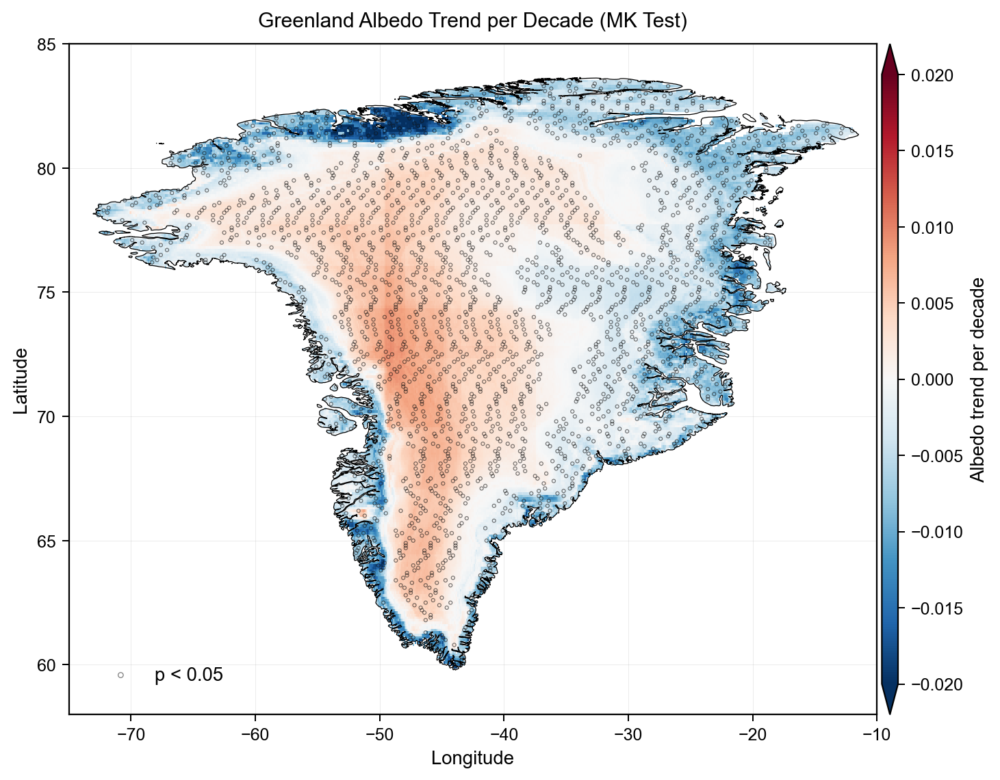

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd

# ===== 路径 =====
csv_path = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend.csv"
shp_path  = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 读数据与处理 =====
df = pd.read_csv(csv_path, sep=None, engine="python",
                 usecols=["lat","lon","trend_per_decade","significant_95pct"])
df["lat"] = np.round(df["lat"].astype(float), 1)
df["lon"] = np.round(df["lon"].astype(float), 1)
df["significant_95pct"] = df["significant_95pct"].astype(str).str.upper().isin(
    ["TRUE","T","1","YES","Y"]
)
df = df.groupby(["lat","lon"], as_index=False).agg(
    trend_per_decade=("trend_per_decade","mean"),
    significant_95pct=("significant_95pct","max")
)

# ===== 构造网格（不插值）=====
lats = np.sort(df["lat"].unique())
lons = np.sort(df["lon"].unique())
dlat = np.median(np.diff(lats))
dlon = np.median(np.diff(lons))
lat_edges = np.arange(lats.min()-dlat/2, lats.max()+dlat/2+dlat*0.01, dlat)
lon_edges = np.arange(lons.min()-dlon/2, lons.max()+dlon/2+dlon*0.01, dlon)

grid = df.pivot(index="lat", columns="lon", values="trend_per_decade")
grid = grid.reindex(index=lats, columns=lons)
Z = np.ma.masked_invalid(grid.values)

# 显著点（抽稀）
sig = df[df["significant_95pct"]].iloc[::20]

# ===== 边界 =====
gld = gpd.read_file(shp_path)
gld = gld.to_crs(epsg=4326) if gld.crs else gld.set_crs(epsg=4326)

# ===== 绘图 =====
plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

fig, ax = plt.subplots(figsize=(8, 16), dpi=180)  # 保持比例与尺寸

# 色阶（红正蓝负，对称0）
norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)
pcm = ax.pcolormesh(lon_edges, lat_edges, Z, cmap="RdBu_r", norm=norm,
                    shading="flat", zorder=2)

# 显著性点
ax.scatter(sig["lon"], sig["lat"], s=4, facecolors="none", edgecolors="#111",
           linewidths=0.5, alpha=0.55, zorder=2.6, label="p < 0.05 ")

# 边界线
gld.boundary.plot(ax=ax, color="black", linewidth=0.5, zorder=4)

# 范围与比例（保持不变）
ax.set_xlim(-75, -10); ax.set_ylim(58, 85)
ax.set_aspect(2, adjustable="box")

# 网格
ax.grid(True, linewidth=0.4, alpha=0.25)

# 轴与标题
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Greenland Albedo Trend per Decade (MK Test)", pad=10)

# ===== 色条贴近主图（不改主图比例）=====
cax = inset_axes(
    ax, width="2.0%", height="100%",
    loc="lower left",
    bbox_to_anchor=(1.006, 0.0, 1.0, 1.0),  # 调第一个数微调间距：1.004更近/1.010更远
    bbox_transform=ax.transAxes,
    borderpad=0
)
cbar = plt.colorbar(pcm, cax=cax, extend="both")
cbar.set_label("Albedo trend per decade")

# ===== 图例：放到图框内左下角 =====
ax.legend(
    loc="lower left",
    bbox_to_anchor=(0.02, 0.02),      # 轴坐标(0~1)内偏移，确保在图框内
    bbox_transform=ax.transAxes,
    frameon=False, fontsize=11, markerscale=1.5
)

# 避免裁切（不动主图比例）
plt.subplots_adjust(left=0.10, right=0.92, top=0.94, bottom=0.08)
plt.show()


📂 正在读取 NetCDF 数据...


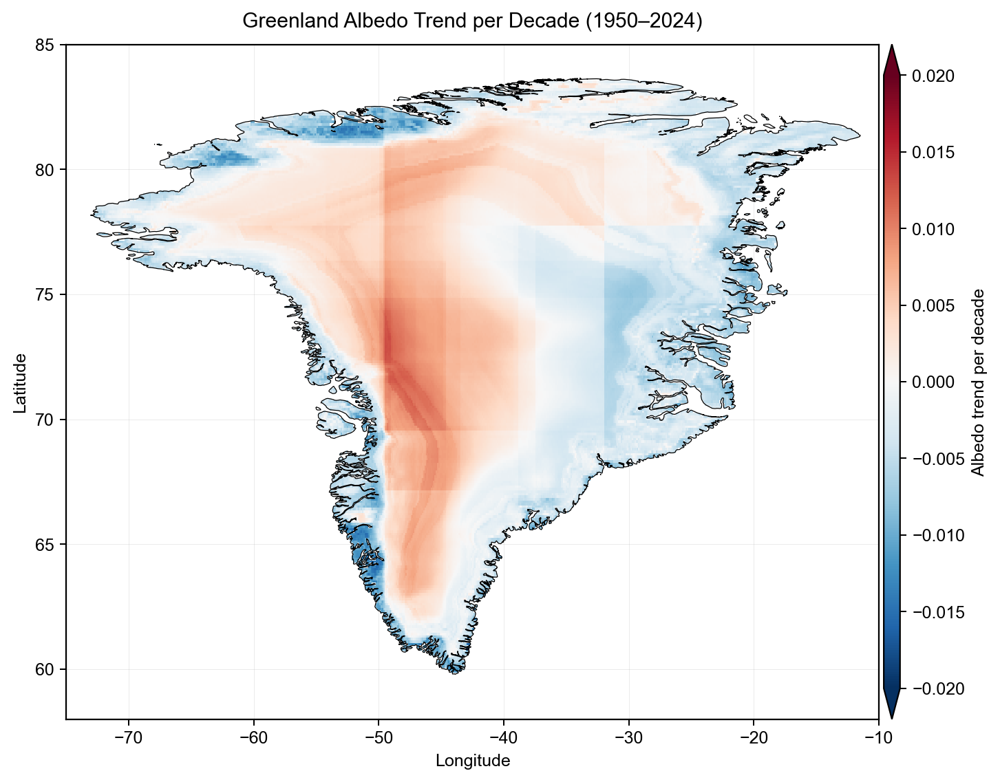

In [ ]:
# -*- coding: utf-8 -*-
"""
Plot Greenland Albedo Trend (from NetCDF + Shapefile)
Author: ChatGPT GPT-5
"""

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd

# ===== 路径 =====
nc_path  = r"C:\Users\11823\era5land\202209202402\albedo_filter202209G.nc"
shp_path = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 读 NetCDF 文件 =====
print("📂 正在读取 NetCDF 数据...")
ds = xr.open_dataset(nc_path)

# 选择变量（此处假设变量名是 "albedo"）
da = ds["albedo"]

# 如果需要计算趋势（每像素随时间线性趋势）
# 也可以直接替换为你已有的 trend_per_decade 数据
time = ds["time"].dt.year + (ds["time"].dt.month - 1) / 12
x = time.values
y = da.values  # shape: [time, lat, lon]

# 计算趋势 (线性最小二乘)
trend = np.empty((da.shape[1], da.shape[2])) * np.nan
for i in range(da.shape[1]):
    for j in range(da.shape[2]):
        y_ij = y[:, i, j]
        if np.isfinite(y_ij).sum() > 10:
            coeff = np.polyfit(x[np.isfinite(y_ij)], y_ij[np.isfinite(y_ij)], 1)
            trend[i, j] = coeff[0] * 10  # 每十年趋势
        else:
            trend[i, j] = np.nan

# ===== 构造经纬度网格 =====
lats = da["lat"].values
lons = da["lon"].values

# ===== 读取格陵兰边界 =====
gld = gpd.read_file(shp_path)
if gld.crs is None:
    gld = gld.set_crs("EPSG:4326")
else:
    gld = gld.to_crs("EPSG:4326")

# ===== 绘图 =====
plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

fig, ax = plt.subplots(figsize=(8, 16), dpi=180)

# 色阶设置
norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)
pcm = ax.pcolormesh(lons, lats, trend, cmap="RdBu_r", norm=norm,
                    shading="auto", zorder=2)

# 边界线
gld.boundary.plot(ax=ax, color="black", linewidth=0.5, zorder=4)

# 范围与比例
ax.set_xlim(-75, -10)
ax.set_ylim(58, 85)
ax.set_aspect(2, adjustable="box")
ax.grid(True, linewidth=0.4, alpha=0.25)

# 轴标签
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Greenland Albedo Trend per Decade (1950–2024)", pad=10)

# ===== 色条 =====
cax = inset_axes(ax, width="2.0%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.006, 0.0, 1.0, 1.0),
                 bbox_transform=ax.transAxes, borderpad=0)
cbar = plt.colorbar(pcm, cax=cax, extend="both")
cbar.set_label("Albedo trend per decade")

plt.subplots_adjust(left=0.10, right=0.92, top=0.94, bottom=0.08)
plt.show()
#==================过滤掉202209-202402的数据训练模型========计算出的趋势============

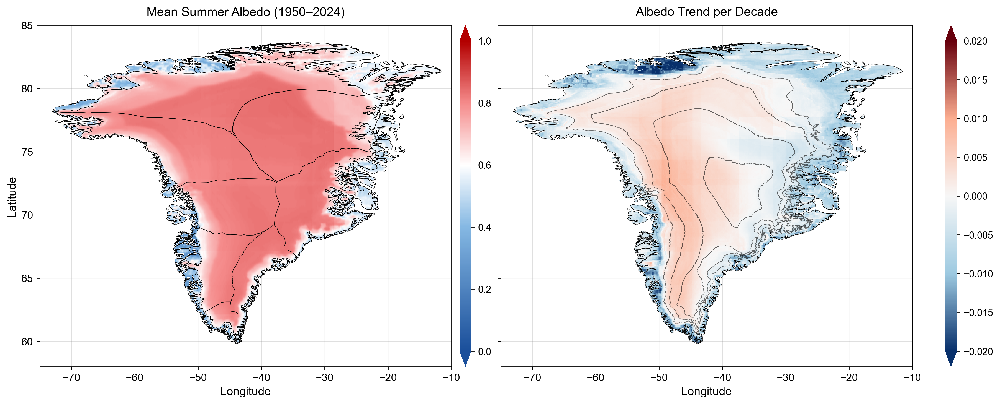

In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd

# ===== 路径 =====
albedo_nc = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
trend_csv = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend.csv"
contour_path = r"C:\greenland\Greenland_shp\等间距等值线.shp"
basin_dir = r"C:\greenland\Greenland_shp\流域冰盖"
boundary_shp = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 1. 读取 albedo 数据并计算长期平均 =====
ds = xr.open_dataset(albedo_nc)
varname = [v for v in ds.data_vars if 'albedo' in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim='time', skipna=True)

lats = albedo_mean['lat'].values
lons = albedo_mean['lon'].values
Z_mean = np.ma.masked_invalid(albedo_mean.values)

# ===== 2. 读取趋势数据 =====
df = pd.read_csv(trend_csv, sep=None, engine="python",
                 usecols=["lat", "lon", "trend_per_decade"])
df["lat"] = np.round(df["lat"].astype(float), 1)
df["lon"] = np.round(df["lon"].astype(float), 1)
df = df.groupby(["lat", "lon"], as_index=False).agg(
    trend_per_decade=("trend_per_decade", "mean")
)
lats_tr = np.sort(df["lat"].unique())
lons_tr = np.sort(df["lon"].unique())
grid = df.pivot(index="lat", columns="lon", values="trend_per_decade")
grid = grid.reindex(index=lats_tr, columns=lons_tr)
Z_trend = np.ma.masked_invalid(grid.values)

# ===== 3. 读取流域和边界 =====
basin_files = [f for f in os.listdir(basin_dir) if f.endswith(".shp")]
basins = gpd.GeoDataFrame(pd.concat(
    [gpd.read_file(os.path.join(basin_dir, f)) for f in basin_files]
), crs="EPSG:4326")

gld = gpd.read_file(boundary_shp)
gld = gld.to_crs(epsg=4326) if gld.crs else gld.set_crs(epsg=4326)

# ===== 4. 读取等高线并筛选500m线 =====
contours = gpd.read_file(contour_path)
contours = contours.to_crs(epsg=4326) if contours.crs else contours.set_crs(epsg=4326)
elev_field = None
for field in ['contour', 'CONTOUR', 'elev', 'ELEV', 'elevation', 'ELEVATION',
              'height', 'HEIGHT', 'Z', 'z']:
    if field in contours.columns:
        elev_field = field
        break
if elev_field:
    contours['elev_num'] = pd.to_numeric(contours[elev_field], errors='coerce')
    contours_500m = contours[contours['elev_num'] % 500 == 0].dropna(subset=['elev_num'])
else:
    contours_500m = contours

# ===== 5. 自定义色图 =====
# 左图：以 0.6 为白色中点的蓝白红渐变
colors_left = [
    (0.00, "#1a4f9b"),  # deep blue
    (0.40, "#85b8e3"),  # soft blue
    (0.60, "#ffffff"),  # white center at 0.6
    (0.80, "#f58b8b"),  # pinkish red
    (1.00, "#b30000")   # strong red (not orange)
]
cmap_left = LinearSegmentedColormap.from_list("mean_albedo_bluewhite", colors_left, N=256)

# 右图：增强红蓝（trend）
colors_right = [
    (0.00, "#08306b"),
    (0.25, "#9ecae1"),
    (0.50, "#f7f7f7"),
    (0.75, "#fcae91"),
    (1.00, "#67000d")
]
cmap_right = LinearSegmentedColormap.from_list("trend_stronger", colors_right, N=256)

# ===== 6. npj 风格参数 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

fig, axes = plt.subplots(1, 2, figsize=(15, 8), dpi=250, sharey=True)
(ax1, ax2) = axes

# ===== 左图：多年平均 Albedo =====
pcm1 = ax1.pcolormesh(lons, lats, Z_mean,
                      cmap=cmap_left, shading="gouraud",  # 平滑渐变
                      vmin=0.0, vmax=1.0,
                      rasterized=True, zorder=2)
basins.boundary.plot(ax=ax1, color='black', linewidth=0.4, zorder=3)
gld.boundary.plot(ax=ax1, color='black', linewidth=0.4, zorder=4)
ax1.set_xlim(-75, -10)
ax1.set_ylim(58, 85)
ax1.set_aspect(2)
ax1.set_xlabel("Longitude", fontsize=12)
ax1.set_ylabel("Latitude", fontsize=12)
ax1.set_title("Mean Summer Albedo (1950–2024)", fontsize=13, pad=10)

# ===== 右图：Trend + DEM 等高线 =====
vmin, vmax = -0.020, 0.020
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
pcm2 = ax2.pcolormesh(lons_tr, lats_tr, Z_trend,
                      cmap=cmap_right, norm=norm,
                      shading="auto", rasterized=True, zorder=2)
contours_500m.plot(ax=ax2, color='black', linewidth=0.4, alpha=0.6, zorder=3)
gld.boundary.plot(ax=ax2, color='black', linewidth=0.4, zorder=4)
ax2.set_xlim(-75, -10)
ax2.set_ylim(58, 85)
ax2.set_aspect(2)
ax2.set_xlabel("Longitude", fontsize=12)
ax2.set_title("Albedo Trend per Decade", fontsize=13, pad=10)

# ===== 色条 =====
# 左色条：向左偏移更多，防止与右图重叠
cax_left = inset_axes(ax1, width="2.8%", height="100%",
                      loc="lower left",
                      bbox_to_anchor=(1.02, 0.0, 1.0, 1.0),
                      bbox_transform=ax1.transAxes, borderpad=0)
cbar_left = plt.colorbar(pcm1, cax=cax_left, extend="both")
#cbar_left.set_label("Mean Albedo", fontsize=12)
cbar_left.outline.set_visible(False)
cbar_left.ax.tick_params(labelsize=10)

# 右色条：略远，保证视觉干净
cax = inset_axes(ax2, width="2.8%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.08, 0.0, 1.0, 1.0),
                 bbox_transform=ax2.transAxes, borderpad=0)
cbar = plt.colorbar(pcm2, cax=cax, extend="both")
#cbar.set_label("Albedo Trend per Decade", fontsize=12)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=10)

# ===== 网格与布局 =====
for ax in axes:
    ax.grid(True, linewidth=0.4, alpha=0.25, color='gray', linestyle='-')

plt.subplots_adjust(left=0.08, right=0.92, top=0.93, bottom=0.08, wspace=0.12)
plt.show()


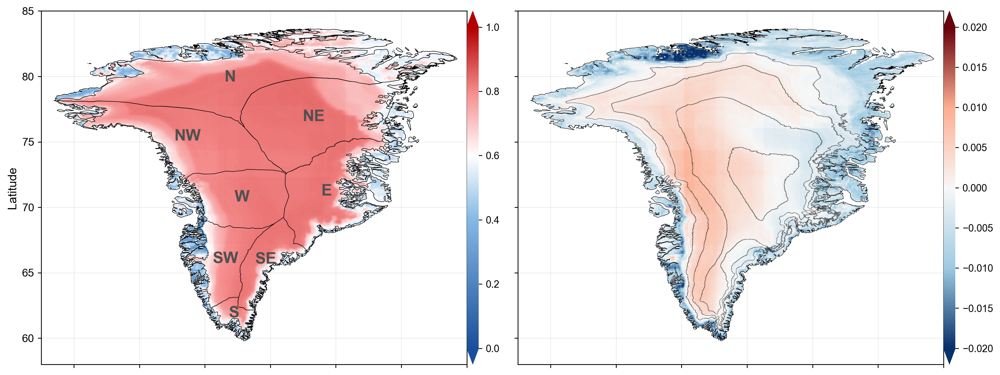

In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd

# ===== 路径 =====
albedo_nc = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
trend_csv = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend.csv"
contour_path = r"C:\greenland\Greenland_shp\等间距等值线.shp"
basin_dir = r"C:\greenland\Greenland_shp\流域冰盖"
boundary_shp = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 1. 读取 albedo 数据并计算长期平均 =====
ds = xr.open_dataset(albedo_nc)
varname = [v for v in ds.data_vars if 'albedo' in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim='time', skipna=True)

lats = albedo_mean['lat'].values
lons = albedo_mean['lon'].values
Z_mean = np.ma.masked_invalid(albedo_mean.values)

# ===== 2. 读取趋势数据 =====
df = pd.read_csv(trend_csv, sep=None, engine="python",
                 usecols=["lat", "lon", "trend_per_decade"])
df["lat"] = np.round(df["lat"].astype(float), 1)
df["lon"] = np.round(df["lon"].astype(float), 1)
df = df.groupby(["lat", "lon"], as_index=False).agg(
    trend_per_decade=("trend_per_decade", "mean")
)
lats_tr = np.sort(df["lat"].unique())
lons_tr = np.sort(df["lon"].unique())
grid = df.pivot(index="lat", columns="lon", values="trend_per_decade")
grid = grid.reindex(index=lats_tr, columns=lons_tr)
Z_trend = np.ma.masked_invalid(grid.values)

# ===== 3. 读取流域（主路径下的9个shp文件）=====
basin_files = [f for f in os.listdir(basin_dir) if f.endswith(".shp")]
basins_list = []
for f in basin_files:
    gdf = gpd.read_file(os.path.join(basin_dir, f))
    # 添加文件名作为标识
    gdf['filename'] = f.replace('.shp', '')
    basins_list.append(gdf)

basins = gpd.GeoDataFrame(pd.concat(basins_list, ignore_index=True), crs="EPSG:4326")

# ===== 流域标签映射（根据实际文件名）=====
label_mapping = {
    'East': 'E',
    'EastNorth': 'NE',
    'EastSouth': 'SE',
    'Melt': ' ',
    'North': 'N',
    'South': 'S',
    'West': 'W',
    'WestNorth': 'NW',
    'WestSouth': 'SW'
}

gld = gpd.read_file(boundary_shp)
gld = gld.to_crs(epsg=4326) if gld.crs else gld.set_crs(epsg=4326)

# ===== 4. 读取等高线并筛选500m线 =====
contours = gpd.read_file(contour_path)
contours = contours.to_crs(epsg=4326) if contours.crs else contours.set_crs(epsg=4326)
elev_field = None
for field in ['contour', 'CONTOUR', 'elev', 'ELEV', 'elevation', 'ELEVATION',
              'height', 'HEIGHT', 'Z', 'z']:
    if field in contours.columns:
        elev_field = field
        break
if elev_field:
    contours['elev_num'] = pd.to_numeric(contours[elev_field], errors='coerce')
    contours_500m = contours[contours['elev_num'] % 500 == 0].dropna(subset=['elev_num'])
else:
    contours_500m = contours

# ===== 5. 自定义色图 =====
colors_left = [
    (0.00, "#1a4f9b"),
    (0.40, "#85b8e3"),
    (0.60, "#ffffff"),
    (0.80, "#f58b8b"),
    (1.00, "#b30000")
]
cmap_left = LinearSegmentedColormap.from_list("mean_albedo_bluewhite", colors_left, N=256)

colors_right = [
    (0.00, "#08306b"),
    (0.25, "#9ecae1"),
    (0.50, "#f7f7f7"),
    (0.75, "#fcae91"),
    (1.00, "#67000d")
]
cmap_right = LinearSegmentedColormap.from_list("trend_stronger", colors_right, N=256)

# ===== 6. npj 风格参数 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

fig, axes = plt.subplots(1, 2, figsize=(15, 8), dpi=250, sharey=True)
(ax1, ax2) = axes

# ===== 左图：多年平均 Albedo =====
pcm1 = ax1.pcolormesh(lons, lats, Z_mean,
                      cmap=cmap_left, shading="gouraud",
                      vmin=0.0, vmax=1.0,
                      rasterized=True, zorder=2)
basins.boundary.plot(ax=ax1, color='black', linewidth=0.4, zorder=3)
gld.boundary.plot(ax=ax1, color='black', linewidth=0.4, zorder=4)

# 添加流域标签（无边框，灰色Arial字体）
for idx, row in basins.iterrows():
    centroid = row.geometry.centroid
    filename = row['filename']
    
    # 查找对应的标签
    label = label_mapping.get(filename, None)
    
    if label:
        ax1.text(centroid.x, centroid.y, label,
                fontsize=16, fontweight='bold',
                family='Arial',
                ha='center', va='center',
                color='#505050',  # 灰色
                zorder=5)

ax1.set_xlim(-75, -10)
ax1.set_ylim(58, 85)
ax1.set_aspect(2)
ax1.set_ylabel("Latitude", fontsize=12)
ax1.tick_params(labelbottom=False)

# ===== 右图：Trend + DEM 等高线 =====
vmin, vmax = -0.020, 0.020
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
pcm2 = ax2.pcolormesh(lons_tr, lats_tr, Z_trend,
                      cmap=cmap_right, norm=norm,
                      shading="auto", rasterized=True, zorder=2)
contours_500m.plot(ax=ax2, color='black', linewidth=0.4, alpha=0.6, zorder=3)
gld.boundary.plot(ax=ax2, color='black', linewidth=0.4, zorder=4)
ax2.set_xlim(-75, -10)
ax2.set_ylim(58, 85)
ax2.set_aspect(2)
ax2.tick_params(labelbottom=False)

# ===== 色条：紧贴右边框 =====
# 左色条
cax_left = inset_axes(ax1, width="2.8%", height="100%",
                      loc="lower left",
                      bbox_to_anchor=(1.0, 0.0, 1.0, 1.0),
                      bbox_transform=ax1.transAxes, borderpad=0)
cbar_left = plt.colorbar(pcm1, cax=cax_left, extend="both")
cbar_left.outline.set_visible(False)
cbar_left.ax.tick_params(labelsize=10)

# 右色条
cax = inset_axes(ax2, width="2.8%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.0, 0.0, 1.0, 1.0),
                 bbox_transform=ax2.transAxes, borderpad=0)
cbar = plt.colorbar(pcm2, cax=cax, extend="both")
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=10)

# ===== 网格与布局 =====
for ax in axes:
    ax.grid(True, linewidth=0.4, alpha=0.25, color='gray', linestyle='-')

plt.subplots_adjust(left=0.08, right=0.92, top=0.96, bottom=0.08, wspace=0.12)
plt.show()

✅ Data range: 1950–2024 (75 years)


C:\Users\11823\AppData\Local\Temp\ipykernel_24328\3220741145.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


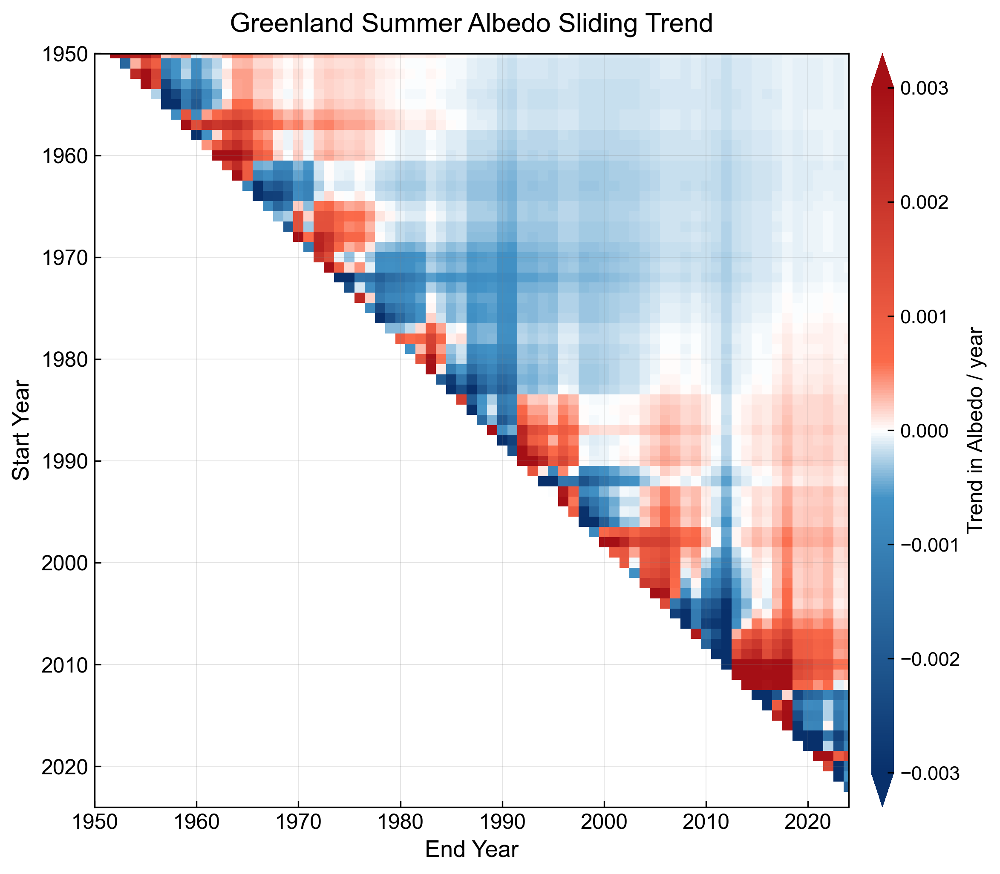

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 (Path - 请根据你的实际路径修改) =====
# 注意：你需要确保这个文件路径是正确的，并且文件存在
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
# 假设文件路径存在且数据结构正确
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含“albedo”的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 核心修改：计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 自定义色图（蓝-白-红，用于趋势） =====
# 这种色图非常适合 Nature 家族期刊风格，清晰地展示了正负趋势。
colors = [
    (0.00, "#08306b"),  # Darkest Blue
    (0.40, "#4292c6"),  # Light Blue
    (0.50, "#ffffff"),  # White Center (0)
    (0.60, "#fb6a4a"),  # Light Red
    (1.00, "#a50f15")   # Darkest Red
]
cmap = LinearSegmentedColormap.from_list("bluewhite_red_trend", colors, N=256)

# ===== 5. 绘图样式参数设置 =====
# 字体设置，推荐使用 Arial 或 Times New Roman 等通用字体
FONT_SIZE = 12 
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in", # 刻度线向内
    "ytick.direction": "in", # 刻度线向内
})

# ===== 6. 绘图 =====
# 调整 figsize 让图表看起来更宽敞
fig, ax = plt.subplots(figsize=(8.0, 7.0), dpi=300) 

# 设置颜色条的范围和中心点（对称色条的规范做法）
vmin, vmax = -0.003, 0.003
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

# 绘制热力图。由于 trend_matrix[i, j] 存储的是 i: Start Year, j: End Year，
# 且 Y 轴反转，所以数据显示在右上角。
pcm = ax.pcolormesh(years, years, trend_matrix,
                    cmap=cmap, norm=norm,
                    shading="auto", rasterized=True)

# ===== 7. 坐标与方向控制与刻度设置 =====
ax.set_xlim(years.min(), years.max())
# 关键：设置 Y 轴从上到下 (1950 在顶部)，与右图一致
ax.set_ylim(years.max(), years.min()) 
ax.set_aspect("equal")
ax.set_facecolor("white") # 背景色保持白色

ax.set_xlabel("End Year", fontsize=FONT_SIZE + 1)
ax.set_ylabel("Start Year", fontsize=FONT_SIZE + 1)
ax.set_title("Greenland Summer Albedo Sliding Trend", fontsize=FONT_SIZE + 3, pad=12)

# 设置主要刻度（每隔10年）
tick_years = np.arange(years.min(), years.max() + 1, 10)
ax.set_xticks(tick_years)
ax.set_yticks(tick_years)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

# ===== 8. 色条（右侧对齐，等高） =====
# 使用 inset_axes 精确控制色条位置和大小
cax = inset_axes(ax, width="3%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.03, 0.0, 1.0, 1.0),
                 bbox_transform=ax.transAxes, borderpad=0)
# extend="both" 表示色条两端有三角，用于超范围的值
cbar = plt.colorbar(pcm, cax=cax, extend="both", 
                    ticks=np.linspace(vmin, vmax, 7)) # 增加刻度数量，更精细
cbar.set_label("Trend in Albedo / year", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE-1)
cbar.outline.set_visible(False) # 移除边框，更简洁

# ===== 9. 网格与版面 =====
# 移除网格线，Nature 风格图表通常不使用网格线，或使用极浅色网格
# ax.grid(False) 
# 如果需要网格，使用以下设置：
ax.grid(True, color="gray", alpha=0.2, linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

ds.close() # 关闭 xarray 数据集


✅ 数据读取成功，形状: (75, 75)
✅ 年份范围: 1950–2024
✅ 起始年份范围: 1950–2024


C:\Users\11823\AppData\Local\Temp\ipykernel_24328\2849176811.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


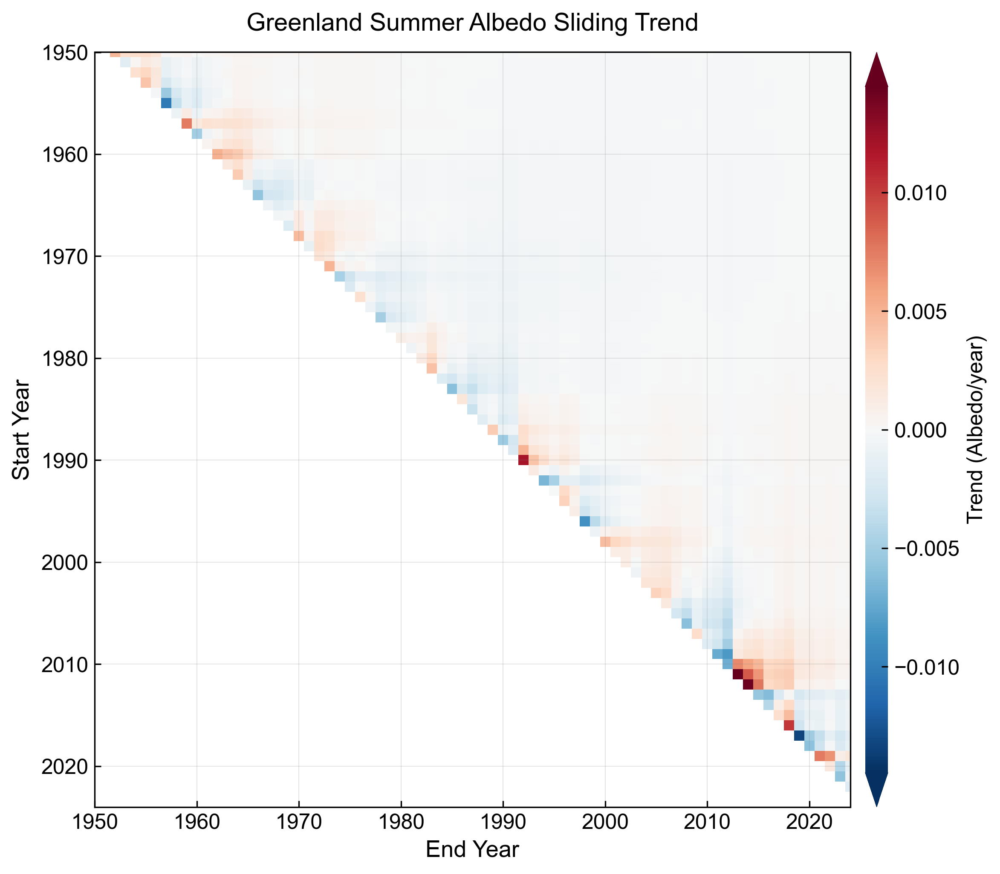

✅ 图片已保存


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径设置 =====
csv_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取 CSV 文件 =====
df = pd.read_csv(csv_path, index_col=0)
print(f"✅ 数据读取成功，形状: {df.shape}")

# ===== 2. 提取年份和数据 =====
years = df.columns.astype(int).values  # 列名转为年份数组
slide_years = df.index.astype(int).values  # 行索引转为年份数组
vals_masked = df.values  # 趋势矩阵

print(f"✅ 年份范围: {years.min()}–{years.max()}")
print(f"✅ 起始年份范围: {slide_years.min()}–{slide_years.max()}")

# ===== 3. 绘图参数设置 =====
FONT_SIZE = 12
CBAR_WIDTH = "3%"
CBAR_PAD = 0.05
UNIT_SLIDE = "Trend (Albedo/year)"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# ===== 4. 创建图形 =====
fig, ax2 = plt.subplots(figsize=(8, 7), dpi=300)

# ===== 5. (3) 滑动趋势热力图 =====
vmax_slide = np.nanmax(np.abs(vals_masked))
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, 
                     cmap="RdBu_r", 
                     norm=norm_slide, 
                     shading="auto",
                     rasterized=True)
ax2.invert_yaxis()

# 色条设置
cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), 
                    bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax, extend='both')
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)

# ===== 6. 样式设置 =====
ax2.tick_params(labelsize=FONT_SIZE)
ax2.set_xlabel("End Year", fontsize=FONT_SIZE + 1)
ax2.set_ylabel("Start Year", fontsize=FONT_SIZE + 1)
ax2.set_title("Greenland Summer Albedo Sliding Trend", fontsize=FONT_SIZE + 2, pad=12)

ax2.set_xticks(np.arange(1950, 2030, 10))
ax2.set_yticks(np.arange(1950, 2030, 10))
ax2.set_aspect('equal')

# 设置坐标轴范围
ax2.set_xlim(years.min(), years.max())
ax2.set_ylim(slide_years.max(), slide_years.min())

# 添加网格（可选）
ax2.grid(True, color="gray", alpha=0.2, linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.savefig(r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.png", 
            dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ 图片已保存")

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import pymannkendall as mk

# --- 1. 文件路径和变量设置 ---
input_file = r"C:\greenland\1995bu\RACMO_greenland_albedo.nc"
csv_output_file = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv"
variable_name = 'alb' 
time_dim_name = 'time' 
trend_factor = 10  # 趋势乘以 10 得到每十年变化量
alpha = 0.05       # 95% 置信度

# --- 2. Mann-Kendall (MK) 核心函数 ---
def mann_kendall_test(data):
    """
    对一维时间序列数据执行 Mann-Kendall 和 Sen's Slope 测试。
    """
    # 移除 NaN 值
    data_clean = data[~np.isnan(data)]
    
    # 如果有效数据点少于 3 个,则无法计算趋势
    if len(data_clean) < 3:
        # 返回 Sen's Slope, P-value
        return np.nan, np.nan
    
    # 使用 pyMannKendall 的 original_test
    result = mk.original_test(data_clean)
    
    # 返回 Sen's Slope 和 P-value
    return result.slope, result.p

# --- 3. 空间计算 (使用 apply_ufunc) ---
try:
    ds = xr.open_dataset(input_file)
    data_array = ds[variable_name]
    
    # 确保时间维度名称存在
    if time_dim_name not in data_array.dims:
        raise ValueError(f"错误: DataArray 的维度中找不到 '{time_dim_name}'。实际维度有: {data_array.dims}")
    
    print(f"成功加载数据,变量: {variable_name},维度: {data_array.dims}")
    
except Exception as e:
    print(f"加载数据时发生错误: {e}")
    exit()

# 使用 apply_ufunc 沿时间维度对每个空间点进行计算
print("开始执行 Mann-Kendall 逐点计算...")
trend_results = xr.apply_ufunc(
    mann_kendall_test,
    data_array,
    input_core_dims=[[time_dim_name]],
    output_core_dims=[[], []],  
    vectorize=True,
    dask='parallelized', 
    output_dtypes=[np.float64, np.float64]
)

# 拆分结果：第一个结果是斜率,第二个是 P-值
trend_slope = trend_results[0].rename('trend_slope_per_year')
p_value = trend_results[1].rename('p_value')

# 计算每十年趋势
trend_per_decade = (trend_slope * trend_factor).rename('trend_per_decade')

# 创建显著性标记 (1 = 显著, 0 = 不显著)
is_significant = (p_value < alpha).astype(int).rename('significant_95pct')

# --- 4. 转换为 CSV 并保存 ---
# 准备用于 CSV 的结果 Dataset
results_ds = xr.Dataset({
    'trend_per_decade': trend_per_decade,
    'p_value': p_value,
    'significant_95pct': is_significant
})

# 将空间数据扁平化并转换为 Pandas DataFrame
df = results_ds.to_dataframe().reset_index()

# 筛选掉 NaN 值（无法计算趋势的格网点）
df = df.dropna(subset=['trend_per_decade'])

# 保存为 CSV 文件
df.to_csv(csv_output_file, index=False)

print(f"\n✅ 趋势计算完成。结果已保存到 CSV: {csv_output_file}")

成功加载数据,变量: alb,维度: ('time', 'height', 'rlat', 'rlon')
开始执行 Mann-Kendall 逐点计算...

✅ 趋势计算完成。结果已保存到 CSV: C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv


正在从NC文件提取真实经纬度坐标...
有效数据点数: 69988
显著点数量: 21451


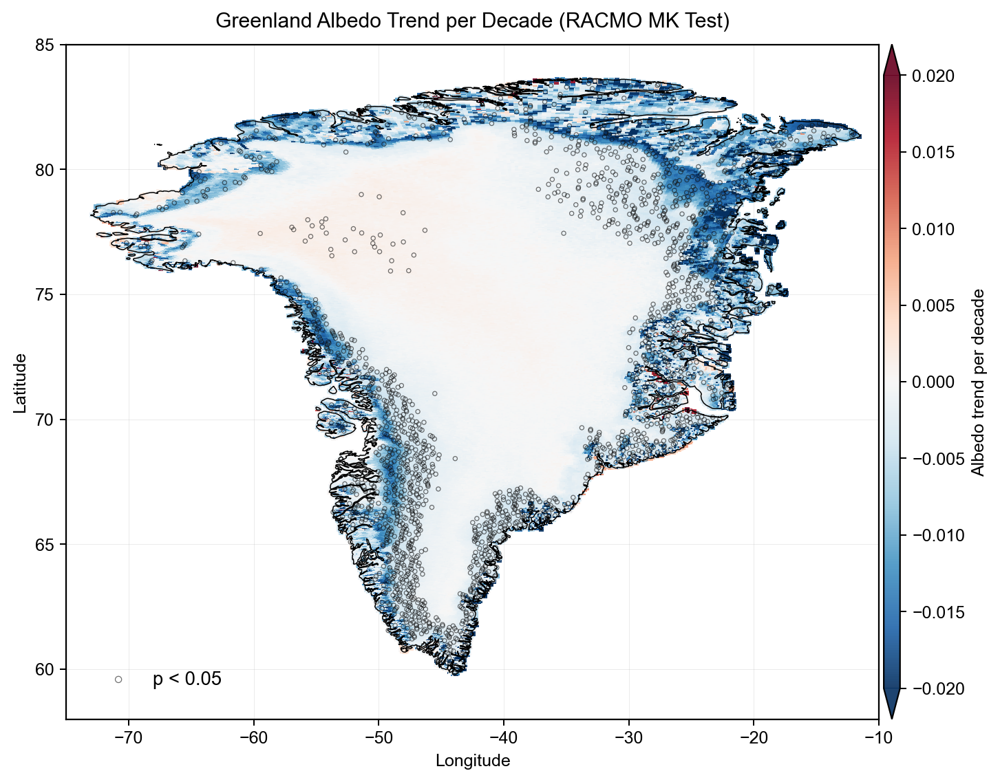

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd
import xarray as xr

# ===== 路径 =====
csv_path = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv"
nc_path  = r"C:\greenland\1995bu\RACMO_greenland_albedo.nc"
shp_path = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 第1步: 从NC文件提取真实经纬度 =====
print("正在从NC文件提取真实经纬度坐标...")
ds = xr.open_dataset(nc_path)

if 'lat' in ds.coords or 'lat' in ds.data_vars:
    lat_2d = ds['lat'].values
    lon_2d = ds['lon'].values
else:
    raise KeyError("NC文件中未找到 'lat' 和 'lon' 变量")

# ===== 第2步: 读取CSV并匹配真实坐标 =====
df = pd.read_csv(csv_path)

# 匹配真实经纬度
df['lat'] = lat_2d[df['rlat'].astype(int), df['rlon'].astype(int)]
df['lon'] = lon_2d[df['rlat'].astype(int), df['rlon'].astype(int)]

# 只保留需要的列
df = df[["lat", "lon", "trend_per_decade", "significant_95pct"]].copy()
df["significant_95pct"] = df["significant_95pct"].astype(bool)

print(f"有效数据点数: {len(df)}")
print(f"显著点数量: {df['significant_95pct'].sum()}")

# 显著点（抽稀）
sig = df[df["significant_95pct"]].iloc[::10]

# ===== 第3步: 读取边界 =====
gld = gpd.read_file(shp_path)
gld = gld.to_crs(epsg=4326) if gld.crs else gld.set_crs(epsg=4326)

# ===== 第4步: 绘图（用散点图代替网格）=====
plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

fig, ax = plt.subplots(figsize=(8, 16), dpi=180)

# 色阶（红正蓝负，对称0）
norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)

# 用scatter绘制趋势（点略大以填充空间）
sc = ax.scatter(df["lon"], df["lat"], c=df["trend_per_decade"], 
                cmap="RdBu_r", norm=norm, s=8, marker='s',  # 's'表示方形点
                edgecolors='none', alpha=0.9, zorder=2)

# 显著性点（空心圆）
ax.scatter(sig["lon"], sig["lat"], s=6, facecolors="none", 
           edgecolors="#111", linewidths=0.5, alpha=0.6, 
           zorder=2.6, label="p < 0.05")

# 边界线
gld.boundary.plot(ax=ax, color="black", linewidth=0.6, zorder=4)

# 范围与比例
ax.set_xlim(-75, -10)
ax.set_ylim(58, 85)
ax.set_aspect(2, adjustable="box")

# 网格
ax.grid(True, linewidth=0.4, alpha=0.25)

# 轴与标题
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Greenland Albedo Trend per Decade (RACMO MK Test)", pad=10)

# ===== 色条 =====
cax = inset_axes(
    ax, width="2.0%", height="100%",
    loc="lower left",
    bbox_to_anchor=(1.006, 0.0, 1.0, 1.0),
    bbox_transform=ax.transAxes,
    borderpad=0
)
cbar = plt.colorbar(sc, cax=cax, extend="both")
cbar.set_label("Albedo trend per decade")

# ===== 图例 =====
ax.legend(
    loc="lower left",
    bbox_to_anchor=(0.02, 0.02),
    bbox_transform=ax.transAxes,
    frameon=False, fontsize=11, markerscale=1.5
)

plt.subplots_adjust(left=0.10, right=0.92, top=0.94, bottom=0.08)
plt.show()

C:\Users\11823\AppData\Local\Temp\ipykernel_148540\4151382964.py:104: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap("RdBu_r")


Saved figure: C:\greenland\1995bu\Fig_Treemap_Greenland_AreaTrend.png
Saved table: C:\greenland\1995bu\Fig_Treemap_Greenland_AreaTrend.csv


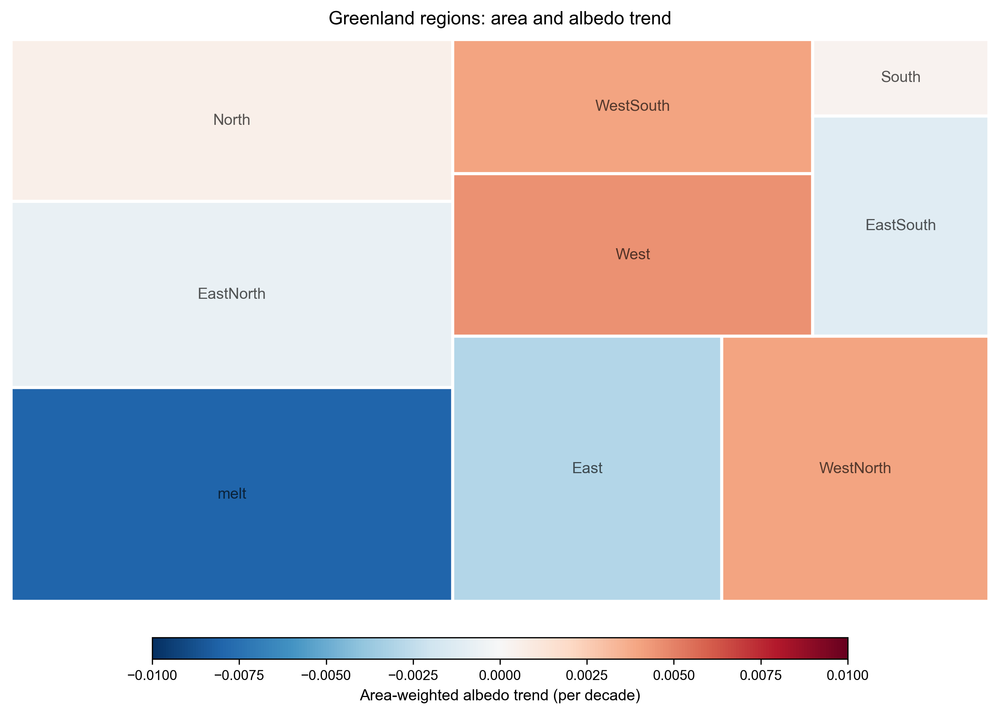

In [ ]:
# -*- coding: utf-8 -*-
"""
Greenland treemap (NPJ风格):
- 矩形面积 = 分区面积 (km²)
- 颜色 = 显著(p<0.05)优先的面积加权albedo趋势 (per decade)
- 风格尽量贴近示例图（大白边、居中标签、零居中色条）
"""

import os, glob
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from pyproj import Geod
import matplotlib.pyplot as plt
import matplotlib as mpl
import squarify

# ========= 路径 =========
CSV_PATH = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend.csv"
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"       # 8个流域shp所在目录（排除 new 子目录）
MELT_SHP  = r"C:\greenland\Greenland_shp\流域冰盖\new\melt.shp"  # 融化区
OUT_PNG   = r"C:\greenland\1995bu\Fig_Treemap_Greenland_AreaTrend.png"

# ========= 读格点数据 =========
df = pd.read_csv(CSV_PATH, sep=None, engine="python")
df.columns = [c.strip() for c in df.columns]
df["significant_95pct"] = df["significant_95pct"].astype(str).str.upper().isin(["TRUE","T","1","YES","Y"])

# —— 按0.1°网格算椭球面积（km²）
DDEG = 0.1
HALF = DDEG/2.0
geod = Geod(ellps="WGS84")

def cell_area_km2(lat, lon, step=DDEG):
    lats = [lat-HALF, lat-HALF, lat+HALF, lat+HALF]
    lons = [lon-HALF, lon+HALF, lon+HALF, lon-HALF]
    area, _ = geod.polygon_area_perimeter(lons, lats)
    return abs(area)/1e6

df["area_km2"] = np.vectorize(cell_area_km2)(df["lat"].values, df["lon"].values)
gdf_pts = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326")

# ========= 读9个分区 =========
# 8个流域（排除 new/ 子目录）
basin_shps = [p for p in glob.glob(os.path.join(BASIN_DIR, "*.shp")) if "new" not in os.path.dirname(p).lower()]
all_region_paths = basin_shps + [MELT_SHP]

regions = []
for shp in all_region_paths:
    g = gpd.read_file(shp)
    if g.crs is None: g.set_crs("EPSG:4326", inplace=True)
    else: g = g.to_crs("EPSG:4326")
    g = g.dissolve().reset_index(drop=True)  # 合并
    name = os.path.splitext(os.path.basename(shp))[0]
    name = {"xiaorong":"Melt zone"}.get(name, name)
    g["region"] = name
    regions.append(g[["region","geometry"]])

gdf_regions = pd.concat(regions, ignore_index=True).set_geometry("geometry")

# ========= 空间匹配：点 ∈ 面 =========
# 注意：predicate='within'（geopandas>=0.10）
join = gpd.sjoin(gdf_pts, gdf_regions, how="inner", predicate="within")

# ========= 逐分区统计 =========
summary = []
for region, grp in join.groupby("region"):
    sig_grp = grp.loc[grp["significant_95pct"] == True]
    use_grp = sig_grp if len(sig_grp)>0 else grp

    w = use_grp["area_km2"].values
    trend = use_grp["trend_per_decade"].values
    wmean_trend = np.average(trend, weights=w) if w.sum()>0 else np.nan

    area_total = grp["area_km2"].sum()
    sig_area_ratio = sig_grp["area_km2"].sum()/area_total if area_total>0 else np.nan

    summary.append({
        "region": region,
        "area_km2": area_total,
        "trend_wmean_per_decade": wmean_trend,
        "sig_area_ratio": sig_area_ratio,
        "n_cells": len(grp),
        "n_sig": len(sig_grp)
    })

sum_df = pd.DataFrame(summary).sort_values("area_km2", ascending=False).reset_index(drop=True)

# ========= 画图（纯手动矩形，风格贴示例） =========
plt.rcParams.update({
    "font.family":"Arial",
    "font.size":10
})

sizes  = sum_df["area_km2"].values
regions= sum_df["region"].values
values = sum_df["trend_wmean_per_decade"].values

# 颜色：零居中
vmax = np.nanmax(np.abs(values)) if np.isfinite(values).any() else 0.01
vmax = max(vmax, 0.01)
norm = mpl.colors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
cmap = mpl.cm.get_cmap("RdBu_r")
colors = [cmap(norm(v)) if np.isfinite(v) else (0.92,0.92,0.92,1.0) for v in values]

fig = plt.figure(figsize=(9.8, 6.5), dpi=300)
# 主绘图区（留出上下方用于标题/色条）
ax = fig.add_axes([0.05, 0.14, 0.90, 0.78])
ax.set_axis_off()
ax.set_facecolor("white")

# 用 squarify 计算布局，但**不用**它的 plot（我们自己画，便于白边风格）
norm_sizes = squarify.normalize_sizes(sizes, 100, 100)
rects = squarify.squarify(norm_sizes, 0, 0, 100, 100)

# 画矩形 + 白色边
for r, col, lab, val, area in zip(rects, colors, regions, values, sizes):
    x, y, dx, dy = r["x"], r["y"], r["dx"], r["dy"]
    # 面块
    ax.add_patch(plt.Rectangle((x, y), dx, dy, facecolor=col, edgecolor="white", linewidth=2))
    # 文本（两行：区域名 + 可选统计）
    label = lab
    # 可选：加一行趋势数值（和示例类似“只写类别”也可以注释掉）
    # label2 = f"{val:+.4f} /dec" if np.isfinite(val) else "NA"
    # 我们保守，用单行名字 + 浅灰字，贴近参考图
    ax.text(x+dx/2, y+dy/2, label, ha="center", va="center",
            color=(0,0,0,0.65), fontsize=10)

ax.set_xlim(0,100); ax.set_ylim(0,100)

# 标题（居中、二级标题）
fig.suptitle("Greenland regions: area and albedo trend", y=0.96, fontsize=12)
fig.text(0.5, 0.915, " ",
         ha="center", va="center", fontsize=10, color=(0,0,0,0.7))

# 色条（水平，零居中，刻度稀疏）
cax = fig.add_axes([0.18, 0.06, 0.64, 0.03])
cb = mpl.colorbar.ColorbarBase(cax, cmap=cmap, norm=norm, orientation="horizontal",
                               ticks=np.linspace(-vmax, vmax, 9))
cb.ax.tick_params(labelsize=9)
cb.set_label("Area-weighted albedo trend (per decade)", fontsize=10)

# 保存
os.makedirs(os.path.dirname(OUT_PNG), exist_ok=True)
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
print("Saved figure:", OUT_PNG)

# 同步导出统计表（供论文/补充材料）
OUT_CSV = OUT_PNG.replace(".png", ".csv")
sum_df.to_csv(OUT_CSV, index=False)
print("Saved table:", OUT_CSV)


In [ ]:
# -*- coding: utf-8 -*-
"""
Step 1 — 检查9个流域分区合并后是否与全冰盖边界一致
"""

import geopandas as gpd
import os, glob
from shapely.ops import unary_union

# ========= 路径 =========
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"   # 只用这一层
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
OUT_DIFF  = r"C:\greenland\Greenland_shp\check_merge_diff.shp"

# ========= 读取9个分区 =========
basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
print(f"检测到 {len(basin_shps)} 个分区文件：")
for shp in basin_shps:
    print("  -", os.path.basename(shp))

gdfs = []
for shp in basin_shps:
    g = gpd.read_file(shp)
    if g.crs is None:
        g.set_crs("EPSG:4326", inplace=True)
    else:
        g = g.to_crs("EPSG:4326")
    g = g.dissolve().reset_index(drop=True)
    gdfs.append(g)

# ========= 合并9个分区 =========
merged = gpd.GeoDataFrame(geometry=[unary_union([geom for g in gdfs for geom in g.geometry])], crs="EPSG:4326")

# ========= 读入全冰盖边界 =========
full = gpd.read_file(FULL_SHP)
if full.crs is None:
    full.set_crs("EPSG:4326", inplace=True)
else:
    full = full.to_crs("EPSG:4326")

# ========= 比较差异 =========
diff = full.overlay(merged, how="difference")

print("\n===== 检查结果 =====")
print(f"差异多边形数量: {len(diff)}")

# 输出面积比较（km²）
full_area = full.to_crs("EPSG:3413").area.sum()/1e6
merged_area = merged.to_crs("EPSG:3413").area.sum()/1e6
diff_area = abs(full_area - merged_area)

print(f"全冰盖面积: {full_area:.2f} km²")
print(f"合并9分区面积: {merged_area:.2f} km²")
print(f"面积差异: {diff_area:.2f} km²")

if len(diff) > 0:
    diff.to_file(OUT_DIFF)
    print(f"⚠ 检测到不完全一致，差异区域已输出: {OUT_DIFF}")
else:
    print("✅ 分区合并结果与主冰盖边界一致。")


检测到 9 个分区文件：
  - East.shp
  - EastNorth.shp
  - EastSouth.shp
  - North.shp
  - South.shp
  - West.shp
  - WestNorth.shp
  - WestSouth.shp
  - melt.shp

===== 检查结果 =====
差异多边形数量: 0
全冰盖面积: 2143693.92 km²
合并9分区面积: 2144891.12 km²
面积差异: 1197.20 km²
✅ 分区合并结果与主冰盖边界一致。


Calculating region: East
Calculating region: EastNorth
Calculating region: EastSouth
Calculating region: Melt
Calculating region: North
Calculating region: South
Calculating region: West
Calculating region: WestNorth
Calculating region: WestSouth
Calculating region: The Entire Greenland Area
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.png


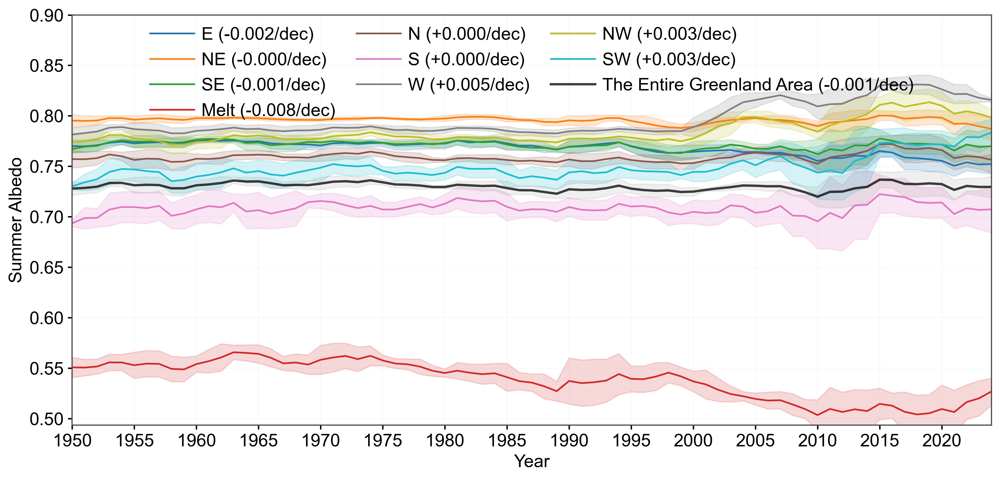

In [ ]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 =========
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
NC_PATH   = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR   = r"C:\greenland\1995bu"
OUT_CSV   = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.csv")
OUT_FIG   = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.png")

# ========= 读取数据 =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取9个分区 + 全格陵兰 =========
regions = []
if albedo is not None:
    basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
    try:
        for shp in basin_shps:
            g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
            name = os.path.splitext(os.path.basename(shp))[0]
            regions.append((name, g))
        full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
        regions.append(("The Entire Greenland Area", full))
    except Exception as e:
        print(f"错误：读取Shapefile失败：{e}")

# ========= 计算时间序列 =========
records = []
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        years = ds["time"].values if not np.issubdtype(ts.index.dtype, np.datetime64) else pd.to_datetime(ts.index).year
        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region", "Year"])
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"]  = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        df = None
else:
    print("❌ 未能成功加载区域或反照率数据")
    df = None

# *************************************************************************
# ************************* START OF USER CUSTOMIZATION BLOCK ***************
# *************************************************************************
LEGEND_Y_OFFSET = 1.01 
# *************************************************************************
# ************************* END OF USER CUSTOMIZATION BLOCK ****************
# *************************************************************************

# ======== 新增：附加每个流域趋势 ========
trend_data = {
    "East": -0.002329151,
    "EastNorth": -0.000280762,
    "EastSouth": -0.000768503,
    "Melt": -0.00770941,
    "North": 0.000276715,
    "South": 0.000362804,
    "West": 0.004832396,
    "WestNorth": 0.003325931,
    "WestSouth": 0.003440071,
    "The Entire Greenland Area": -0.000666594
}

# --- 新增: 区域名称缩写映射 (按照用户要求修改) ---
name_map = {
    "East": "E", 
    "EastNorth": "NE", # 北东 (North-East)
    "EastSouth": "SE", # 南东 (South-East)
    "Melt": "Melt", 
    "North": "N", 
    "South": "S",
    "West": "W", 
    "WestNorth": "NW", # 北西 (North-West)
    "WestSouth": "SW", # 南西 (South-West)
    "The Entire Greenland Area": "The Entire Greenland Area" 
}
# ------------------------------------------------

# ========= 绘图 =========
if df is not None:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
    if regions:
        num_basins = len(regions) - 1
        colors = plt.cm.tab10(np.linspace(0,1,num_basins))

        # 绘制9个分区
        for (name, _), col in zip(regions[:-1], colors):
            grp = df[df["Region"] == name]
            
            # 使用缩写和趋势值创建标签
            display_name = name_map.get(name, name)
            trend_val = trend_data.get(name, np.nan)
            label = f"{display_name} ({trend_val:+.3f}/dec)" 
            
            ax.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4, label=label)
            ax.fill_between(grp["Year"],
                            grp["mean_5yr"] - grp["std_5yr"],
                            grp["mean_5yr"] + grp["std_5yr"],
                            color=col, alpha=0.18)

        # 绘制全格陵兰
        gall = df[df["Region"] == "The Entire Greenland Area"]
        # 使用缩写(全称)和趋势值创建全格陵兰标签
        gall_label = f"{name_map['The Entire Greenland Area']} ({trend_data['The Entire Greenland Area']:+.3f}/dec)"
        
        ax.plot(gall["Year"], gall["mean_5yr"], color="k", lw=2.0, alpha=0.75, label=gall_label)
        ax.fill_between(gall["Year"],
                        gall["mean_5yr"] - gall["std_5yr"],
                        gall["mean_5yr"] + gall["std_5yr"],
                        color="gray", alpha=0.12)

    # ======== 图形美化 ========
    ax.set_xlabel("Year", fontsize=15)
    ax.set_ylabel("Summer Albedo", fontsize=15)
    ax.set_xlim(1950, 2024)
    ax.set_xticks(np.arange(1950, 2025, 5))
    min_albedo = df["mean_5yr"].min() if not df.empty else 0.5
    ax.set_ylim(min_albedo - 0.01, 0.9)
    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
        ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
    ax.grid(alpha=0.15, linewidth=0.4)

    # ======== 图例改为3行 ========
    ax.legend(
        frameon=False, fontsize=15, ncol=3, loc="upper center",
        bbox_to_anchor=(0.5, LEGEND_Y_OFFSET),
        handlelength=2.5, handletextpad=0.4, columnspacing=1.2
    )

    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成。")

Calculating region: East
Calculating region: EastNorth
Calculating region: EastSouth
Calculating region: Melt
Calculating region: North
Calculating region: South
Calculating region: West
Calculating region: WestNorth
Calculating region: WestSouth
Calculating region: The Entire Greenland Area
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries_TrendBar_V1.png


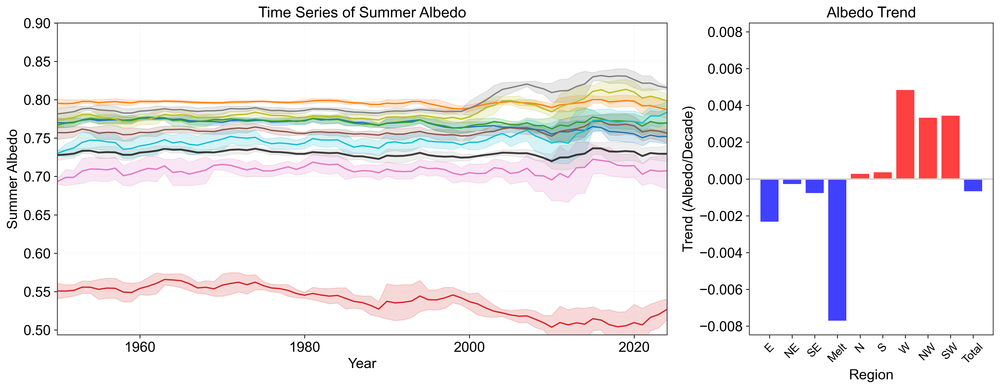

In [ ]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 (使用用户提供的路径，假定它们已存在) =========
# ‼️ 确保这些路径在您的环境中是正确的 ‼️
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP = r"C:\greenland\Greenland_shp\Gboundry.shp"
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR  = r"C:\greenland\1995bu"
OUT_CSV  = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.csv")
# 输出文件名
OUT_FIG  = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries_TrendBar_V1.png")

# ========= 读取数据 (原始代码块) =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取9个分区 + 全格陵兰 (原始代码块) =========
regions = []
if albedo is not None:
    basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
    try:
        for shp in basin_shps:
            g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
            name = os.path.splitext(os.path.basename(shp))[0]
            regions.append((name, g))
        full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
        regions.append(("The Entire Greenland Area", full))
    except Exception as e:
        print(f"错误：读取Shapefile失败：{e}")

# ========= 计算时间序列 (原始代码块，已修复语法错误) =========
records = []
df = None # 预先初始化 df
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        # 假设 time 坐标在 xarray 中是年份或可转换为年份
        years = ds["time"].values if not np.issubdtype(ts.index.dtype, np.datetime64) else pd.to_datetime(ts.index).year
        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region", "Year"])
        
        # ⬇️ 修复了不可见字符 U+00A0 导致的 SyntaxError ⬇️
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        print("❌ 未能计算任何时间序列")
        df = None
else:
    print("❌ 未能成功加载区域或反照率数据")
    df = None


# ======== 附加每个流域趋势 (用户数据) ========
trend_data = {
    "East": -0.002329151,
    "EastNorth": -0.000280762,
    "EastSouth": -0.000768503,
    "Melt": -0.00770941,
    "North": 0.000276715,
    "South": 0.000362804,
    "West": 0.004832396,
    "WestNorth": 0.003325931,
    "WestSouth": 0.003440071,
    "The Entire Greenland Area": -0.000666594
}

# --- 区域名称缩写映射 (按最新要求 Total) ---
name_map = {
    "East": "E", 
    "EastNorth": "NE", 
    "EastSouth": "SE", 
    "Melt": "Melt", 
    "North": "N", 
    "South": "S",
    "West": "W", 
    "WestNorth": "NW", 
    "WestSouth": "SW", 
    "The Entire Greenland Area": "Total" 
}

# ========= 绘图 (按 V1 要求修改) =========
if df is not None:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    # 创建包含两个子图的画布: ax1 (折线图), ax2 (柱状图)
    fig, (ax1, ax2) = plt.subplots(
        nrows=1, ncols=2, 
        figsize=(15, 6), 
        dpi=300, 
        sharey=False, 
        gridspec_kw={'width_ratios': [2.5, 1]} # 宽度比例
    )

    if regions:
        # 获取分区名称列表 (不含全格陵兰)
        basin_names = [name for name, _ in regions[:-1]]
        num_basins = len(basin_names)
        colors = plt.cm.tab10(np.linspace(0,1,num_basins))
        
        # --- 1. 绘制左侧折线图 (ax1) ---
        
        # 绘制9个分区
        for name, col in zip(basin_names, colors):
            grp = df[df["Region"] == name]
            ax1.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4)
            ax1.fill_between(grp["Year"],
                             grp["mean_5yr"] - grp["std_5yr"],
                             grp["mean_5yr"] + grp["std_5yr"],
                             color=col, alpha=0.18)

        # 绘制全格陵兰
        gall = df[df["Region"] == "The Entire Greenland Area"]
        ax1.plot(gall["Year"], gall["mean_5yr"], color="k", lw=2.0, alpha=0.75)
        ax1.fill_between(gall["Year"],
                         gall["mean_5yr"] - gall["std_5yr"],
                         gall["mean_5yr"] + gall["std_5yr"],
                         color="gray", alpha=0.12)

        # --- 折线图 (ax1) 美化和修改 ---
        ax1.set_xlabel("Year", fontsize=15)
        ax1.set_ylabel("Summer Albedo", fontsize=15)
        ax1.set_xlim(1950, 2024)
        ax1.set_xticks(np.arange(1960, 2021, 20)) # X轴改为20年一刻度
        
        min_albedo = df["mean_5yr"].min() if not df.empty else 0.5
        ax1.set_ylim(min_albedo - 0.01, 0.9)
        
        ax1.grid(alpha=0.15, linewidth=0.4)
        ax1.set_title("Time Series of Summer Albedo", fontsize=16)


        # --- 2. 绘制右侧柱状图 (ax2) ---
        
        trends_df = pd.Series(trend_data).reset_index()
        trends_df.columns = ['Region', 'Trend']
        trends_df['Region_Short'] = trends_df['Region'].map(name_map)
        
        # 确保柱子顺序正确
        sort_order = [name for name, _ in regions[:-1]] + ["The Entire Greenland Area"]
        trends_df = trends_df.set_index('Region').loc[sort_order].reset_index()
        
        # 设定柱状图颜色：正值红色，负值蓝色
        bar_colors_trends = ['red' if t > 0 else 'blue' for t in trends_df['Trend']]
        
        # 绘制柱状图
        ax2.bar(
            x=trends_df['Region_Short'], 
            height=trends_df['Trend'], 
            color=bar_colors_trends, 
            alpha=0.75
        )
        
        # --- 柱状图 (ax2) 美化 ---
        ax2.axhline(0, color='lightgray', linestyle='-', linewidth=1.5) # 零线
        
        ax2.set_xlabel("Region", fontsize=15)
        ax2.set_ylabel("Trend (Albedo/Decade)", fontsize=15)
        
        ax2.tick_params(axis='x', rotation=45, labelsize=12)
        
        # 调整Y轴范围，使其居中于零点
        max_abs_trend = trends_df['Trend'].abs().max()
        y_lim_pad = max_abs_trend * 0.1
        ax2.set_ylim(-max_abs_trend - y_lim_pad, max_abs_trend + y_lim_pad)
        ax2.set_title("Albedo Trend", fontsize=16)

        # 调整所有子图的边框
        for ax in [ax1, ax2]:
            for spine in ['top', 'bottom', 'left', 'right']:
                ax.spines[spine].set_visible(True)
                ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
                ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
        
    fig.tight_layout()
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成。")

In [4]:
# -*- coding: utf-8 -*-
"""
修正版：添加 albedo 流域时间序列计算 (Greenland_albedo1950-2024.nc)
"""
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import rioxarray
from shapely.geometry import mapping

# ========================= 路径配置 =========================
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"

PATH_HCLCVIMF = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc"
PATH_ALBEDO   = r"C:\greenland\1995bu\Greenland_albedo1950-2024.nc"

OUT_DIR  = r"C:\greenland\1995bu\OtherVariables"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_CSV  = os.path.join(OUT_DIR, "Fig_Greenland_AllBasin_TimeSeries.csv")

VARIABLE_MAP = {
    'hc': PATH_HCLCVIMF,
    'lc': PATH_HCLCVIMF,
    'vimdf': PATH_HCLCVIMF,
    'alb': PATH_ALBEDO
}

# ========================= 工具函数 =========================

def safe_open_nc(nc_path, var_name):
    print(f"\n--- 正在打开文件: {os.path.basename(nc_path)} → {var_name} ---")

    name_map = {'hc': 'hcc', 'lc': 'lcc', 'vimdf': 'vimdf', 'alb': 'albedo'}
    var_nc = name_map.get(var_name, var_name)

    try:
        ds = xr.open_dataset(nc_path)
    except Exception:
        ds = xr.open_dataset(nc_path, engine="h5netcdf")
        print(f"⚙️ 用 h5netcdf 成功打开 {os.path.basename(nc_path)}")

    if var_nc not in ds:
        print(f"❌ {var_nc} 不在 {os.path.basename(nc_path)} 中, 可用变量: {list(ds.keys())}")
        return None

    da = ds[var_nc]

    # 统一维度
    for cand in ["time", "valid_time"]:
        if cand in da.dims:
            if cand != "time":
                da = da.rename({cand: "time"})
            break

    rename_dict = {}
    if "latitude" in da.dims: rename_dict["latitude"] = "lat"
    if "longitude" in da.dims: rename_dict["longitude"] = "lon"
    if rename_dict:
        da = da.rename(rename_dict)

    # CRS
    try:
        da.rio.set_spatial_dims(x_dim="lon", y_dim="lat", inplace=True)
        if not da.rio.crs:
            da.rio.write_crs("EPSG:4326", inplace=True)
    except Exception as e:
        print(f"⚠️ CRS 设置失败: {e}")

    return da


def process_to_annual_summer_mean(da, var_name):
    """提取夏季 (6,7,8月) 平均并按年聚合"""
    if "time" not in da.dims:
        return None
    try:
        da = da.sel(time=da.time.dt.month.isin([6,7,8]))
        out = da.groupby("time.year").mean("time", skipna=True)
        out = out.rename({"year": "time"})
        print(f"✅ {var_name} 夏季年度平均完成。")
        return out
    except Exception as e:
        print(f"❌ {var_name} 夏季平均出错: {e}")
        return None


def calculate_time_series_for_all_regions(annual_da, regions, var_name):
    """计算每个流域的时间序列"""
    records = []
    print(f"➡️ 计算 {var_name} 的流域时间序列...")
    for name, g in regions:
        try:
            clipped = annual_da.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
            ts = clipped.mean(dim=("lat", "lon"), skipna=True).to_pandas()
            df = pd.DataFrame({
                "Year": ts.index.values,
                "Value": ts.values,
                "Region": name,
                "Variable": var_name
            })
            records.append(df)
        except Exception as e:
            print(f"❌ 区域 {name} 出错: {e}")
    return pd.concat(records, ignore_index=True) if records else None


# ========================= 主流程 =========================

# 读取流域
regions = []
basin_files = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
for shp in basin_files:
    g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
    name = os.path.splitext(os.path.basename(shp))[0]
    regions.append((name, g))
full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
regions.append(("The Entire Greenland Area", full))
print("✅ 区域 Shapefile 读取完成。")

# 读取已有 CSV
if os.path.exists(OUT_CSV):
    df_existing = pd.read_csv(OUT_CSV)
    df_existing["Year"] = pd.to_numeric(df_existing["Year"], errors="coerce").astype("Int64")
    df_existing["Value"] = pd.to_numeric(df_existing["Value"], errors="coerce")
    existing_vars = set(df_existing["Variable"].dropna().unique())
    print(f"📘 已存在变量: {sorted(existing_vars)}")
else:
    df_existing = pd.DataFrame()
    existing_vars = set()

# 仅计算缺失变量
all_df = []
for var, path in VARIABLE_MAP.items():
    if var in existing_vars:
        print(f"⏩ 跳过已完成变量: {var}")
        continue

    da = safe_open_nc(path, var)
    if da is None:
        continue
    da_summer = process_to_annual_summer_mean(da, var)
    if da_summer is None:
        continue
    df = calculate_time_series_for_all_regions(da_summer, regions, var)
    if df is not None:
        df["Year"] = pd.to_numeric(df["Year"], errors="coerce").astype("Int64")
        df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
        all_df.append(df)

# 合并保存
if all_df:
    df_new = pd.concat(all_df, ignore_index=True)
    df_final = pd.concat([df_existing, df_new], ignore_index=True)
    df_final.to_csv(OUT_CSV, index=False)
    print("\n===================================================")
    print(f"✅ 新变量计算完成并合并保存至: {OUT_CSV}")
    print("===================================================")
else:
    print("⚠️ 无新变量需要计算。")


✅ 区域 Shapefile 读取完成。
📘 已存在变量: ['hc', 'lc', 'rf', 'sf', 'ssrd', 'strd', 't2m', 'tcc', 'tp', 'vimdf']
⏩ 跳过已完成变量: hc
⏩ 跳过已完成变量: lc
⏩ 跳过已完成变量: vimdf

--- 正在打开文件: Greenland_albedo1950-2024.nc → alb ---
✅ alb 夏季年度平均完成。
➡️ 计算 alb 的流域时间序列...

✅ 新变量计算完成并合并保存至: C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv


C:\Users\11823\AppData\Local\Temp\ipykernel_28884\733710126.py:152: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(region_order, fontsize=10, rotation=0)
C:\Users\11823\AppData\Local\Temp\ipykernel_28884\733710126.py:169: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


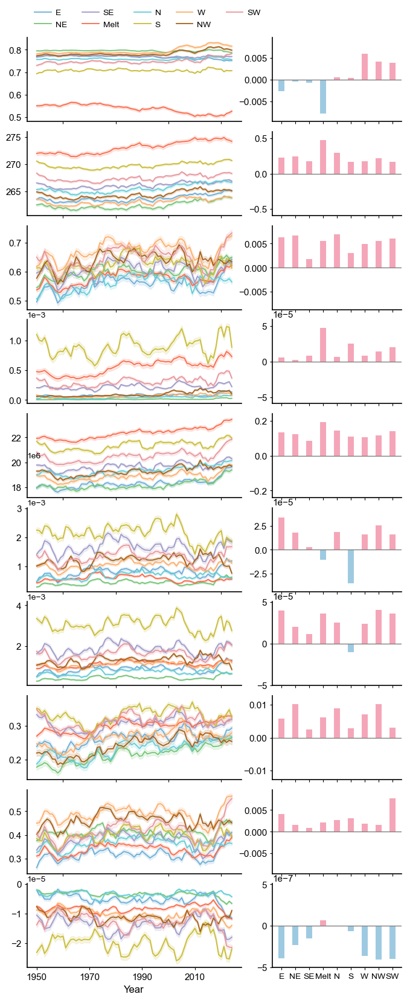

In [9]:
# -*- coding: utf-8 -*-
"""
NPJ-style Greenland Multi-Variable Time Series + Trend Panel (Refined v10)
→ SSRD/STRD 人工 “1e6” 与 Matplotlib 自动科学计数标识位置完全一致；
→ 字号统一、不加粗；布局稳定无死循环。
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import linregress
# 移除 from matplotlib.ticker import ScalarFormatter 和 CustomScalarFormatter

# ========= 参数 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_TimeseriesTrend_AllVar_v10_final_adjust_v5.png" # 再次更新保存路径

variables = ["albedo", "t2m", "tcc", "rf", "strd", "sf", "tp", "hcc", "lcc", "vimdf"]
var_labels = {
    'albedo':'ALBEDO','hcc':'HCC','lcc':'LCC','rf':'RF','sf':'SF',
    'strd':'STRD','t2m':'T2M','tcc':'TCC','tp':'TP','vimdf':'VIMDF' 
}
region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Total']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Total':'#969696'
}

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

# ========= 数据 & 函数 (不变) =========
df = pd.read_csv(CSV_PATH)
variable_mapping = {
    'alb': 'albedo', 'hc': 'hcc', 'lc': 'lcc', 'rf': 'rf', 'sf': 'sf',
    'ssrd': 'ssrd', 'strd': 'strd', 't2m': 't2m', 'tcc': 'tcc',
    'tp': 'tp', 'vimdf': 'vimdf'
}
df['Variable'] = df['Variable'].replace(variable_mapping)
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW','Total':'Total'
})
def calc_trend(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    slope, _, _, p, _ = linregress(x[mask], y[mask])
    return slope * 10, p

# ========= 绘图 =========
n_var = len(variables)

# 保持宽度 8，高度 n_var * 2.0
fig = plt.figure(figsize=(8, n_var * 2.0)) 
# 保持 width_ratios=[1.2, 0.72]
gs = GridSpec(n_var, 2, width_ratios=[1.2, 0.72], wspace=0.18, hspace=0.12)
handles, labels = [], []


for i, var in enumerate(variables):
    sub = df[df['Variable'] == var].copy()
    
    if var in ['ssrd', 'strd']: 
        sub['Value'] = sub['Value'] / 1e6

    # ---- 折线图 ----
    ax1 = fig.add_subplot(gs[i, 0])
    for r in region_order:
        dat = sub[sub['Region'] == r].sort_values('Year')
        if dat.empty:
            continue
        y = dat['Value'].rolling(5, center=True, min_periods=1).mean()
        line, = ax1.plot(dat['Year'], y, color=colors[r], lw=1.3)
        if i == 0:
             handles.append(line)
             labels.append(r)
        
        ax1.fill_between(dat['Year'], y - y.std()/3, y + y.std()/3,
                          color=colors[r], alpha=0.15)

    # ---- 轴样式 ----
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    if i < n_var - 1:
        ax1.set_xticklabels([])
    else:
        ax1.set_xlabel("Year", fontsize=12)
        ax1.set_xticks(np.arange(1950, 2030, 20))
    ax1.tick_params(direction='out', length=3)

    # ---- 科学计数法 ----
    if var in ['ssrd', 'strd']: 
        # 对 ssrd/strd 保持 style='plain'，并手动添加 '1e6'
        ax1.ticklabel_format(axis='y', style='plain')
    else:
        # 对其他变量使用 style='sci'
        ax1.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))

    # ---- 调整自动 offset_text 样式 (位置和格式统一) ----
    offset_text = ax1.yaxis.get_offset_text()
    offset_text.set_fontsize(10)
    offset_text.set_fontweight('normal')
    offset_text.set_color('black')
    
    # 保持位置统一下移
    offset_text.set_y(offset_text.get_position()[1] - 0.05) 

    # **【核心修正】** 修正 offset_text 格式 (将 '1e' 替换为 'e' 的核心逻辑)
    # 这一步必须在 ticklabel_format 之后执行
    if offset_text.get_text():
        # 获取当前文本，移除 Matplotlib 默认添加的 '1'
        text = offset_text.get_text().replace(r'10^{', r'e') 
        # 兼容 Matplotlib 旧版本可能输出的 '1e' 格式
        text = text.replace('1e', 'e')
        offset_text.set_text(text)

    # ---- 对 STRD 手动添加与自动 offset 相同位置的 “1e6” ----
    if var in ['ssrd', 'strd']: 
        ref_pos = offset_text.get_position()
        ax1.text(ref_pos[0], ref_pos[1], "1e6",
                  transform=ax1.transAxes,
                  fontsize=10, color='black',
                  ha='left', va='bottom')

    # ---- 柱状趋势 ----
    ax2 = fig.add_subplot(gs[i, 1])
    trends, pvals = [], []
    for r in region_order:
        dat = sub[sub['Region'] == r]
        if dat.empty:
            trends.append(np.nan); pvals.append(np.nan); continue
        slope, p = calc_trend(dat['Year'].values, dat['Value'].values)
        trends.append(slope); pvals.append(p)

    cols = ['#f4a6b8' if t > 0 else '#9ecae1' for t in trends]
    ax2.bar(region_order, trends, color=cols, width=0.45)
    ax2.axhline(0, color='gray', lw=1)
    if np.isfinite(trends).any():
        lim = np.nanmax(np.abs(trends)) * 1.25
        ax2.set_ylim(-lim, lim)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.tick_params(direction='out', length=3)
    if i < n_var - 1:
        ax2.set_xticklabels([])
    else:
        # 保持 rotation=0，并依赖增加的宽度解决重叠问题
        ax2.set_xticklabels(region_order, fontsize=10, rotation=0) 
        ax2.set_xlabel("")
    ax2.set_title("") 

# **【图例修正】** y 调整到 1.02，更紧贴
ax1_first = fig.axes[0] 
ax1_first.legend(handles, labels, 
                 ncol=5, 
                 loc='lower left', 
                 bbox_to_anchor=(0, 1.02), # 进一步拉近
                 fontsize=10, frameon=False, 
                 columnspacing=1.8, handletextpad=0.5)


# ---- 稳定布局 ----
fig.set_constrained_layout(True) 

plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

C:\Users\11823\AppData\Local\Temp\ipykernel_28636\3750265849.py:151: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(region_order, fontsize=10, rotation=0)
C:\Users\11823\AppData\Local\Temp\ipykernel_28636\3750265849.py:169: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


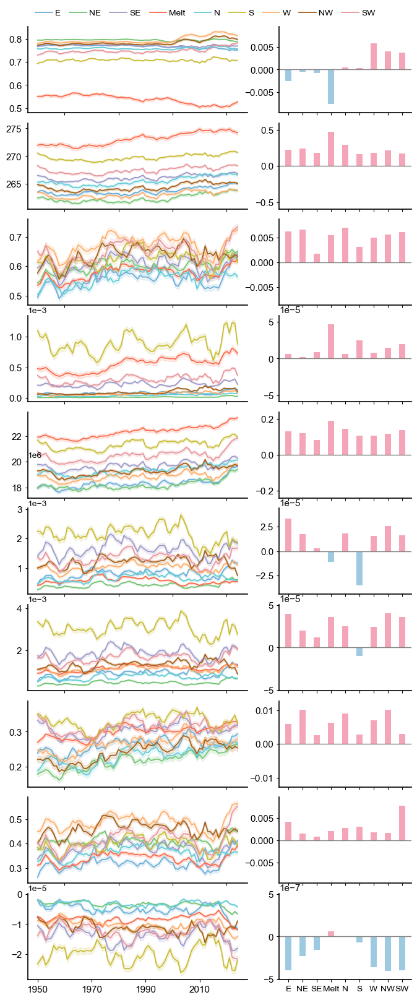

In [2]:
# -*- coding: utf-8 -*-
"""
NPJ-style Greenland Multi-Variable Time Series + Trend Panel (Refined v10)
→ SSRD/STRD 人工 “1e6” 与 Matplotlib 自动科学计数标识位置完全一致；
→ 字号统一、不加粗；布局稳定无死循环。
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import linregress
# 移除 from matplotlib.ticker import ScalarFormatter 和 CustomScalarFormatter

# ========= 参数 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_TimeseriesTrend_AllVar_v10_final_adjust_v7.png" # 更新保存路径

variables = ["albedo", "t2m", "tcc", "rf", "strd", "sf", "tp", "hcc", "lcc", "vimdf"]
# **【修正 U+00A0 错误】** 确保这里只有标准空格
var_labels = {
    'albedo':'ALBEDO','hcc':'HCC','lcc':'LCC','rf':'RF','sf':'SF',
    'strd':'STRD','t2m':'T2M','tcc':'TCC','tp':'TP','vimdf':'VIMDF' 
}
region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Total']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Total':'#969696'
}

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

# ========= 数据 & 函数 (不变) =========
df = pd.read_csv(CSV_PATH)
variable_mapping = {
    'alb': 'albedo', 'hc': 'hcc', 'lc': 'lcc', 'rf': 'rf', 'sf': 'sf',
    'ssrd': 'ssrd', 'strd': 'strd', 't2m': 't2m', 'tcc': 'tcc',
    'tp': 'tp', 'vimdf': 'vimdf'
}
df['Variable'] = df['Variable'].replace(variable_mapping)
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW','Total':'Total'
})
def calc_trend(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    slope, _, _, p, _ = linregress(x[mask], y[mask])
    return slope * 10, p

# ========= 绘图 =========
n_var = len(variables)

# 保持宽度 8，高度 n_var * 2.0
fig = plt.figure(figsize=(8, n_var * 2.0)) 
# 保持 width_ratios=[1.2, 0.72]
gs = GridSpec(n_var, 2, width_ratios=[1.2, 0.72], wspace=0.18, hspace=0.12)
handles, labels = [], []


for i, var in enumerate(variables):
    sub = df[df['Variable'] == var].copy()
    
    if var in ['ssrd', 'strd']: 
        sub['Value'] = sub['Value'] / 1e6

    # ---- 折线图 ----
    ax1 = fig.add_subplot(gs[i, 0])
    for r in region_order:
        dat = sub[sub['Region'] == r].sort_values('Year')
        if dat.empty:
            continue
        y = dat['Value'].rolling(5, center=True, min_periods=1).mean()
        line, = ax1.plot(dat['Year'], y, color=colors[r], lw=1.3)
        if i == 0:
             handles.append(line)
             labels.append(r)
        
        ax1.fill_between(dat['Year'], y - y.std()/3, y + y.std()/3,
                            color=colors[r], alpha=0.15)

    # ---- 轴样式 ----
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    if i < n_var - 1:
        ax1.set_xticklabels([])
    else:
        # **【修改 1】** 注释掉 ax1.set_xlabel("Year")
        # ax1.set_xlabel("Year", fontsize=12) 
        ax1.set_xticks(np.arange(1950, 2030, 20))
    ax1.tick_params(direction='out', length=3)

    # ---- 科学计数法 ----
    if var in ['ssrd', 'strd']: 
        ax1.ticklabel_format(axis='y', style='plain')
    else:
        ax1.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))

    # ---- 调整自动 offset_text 样式 (位置和格式统一) ----
    offset_text = ax1.yaxis.get_offset_text()
    offset_text.set_fontsize(10)
    offset_text.set_fontweight('normal')
    offset_text.set_color('black')
    
    # 保持位置统一下移（统一到上部）
    offset_text.set_y(offset_text.get_position()[1] - 0.05) 

    # **【科学计数法格式修正】** 修正 offset_text 格式 (将 '1e' 替换为 'e' 的核心逻辑)
    if offset_text.get_text():
        # 匹配 Matplotlib 的 LaTeX 格式： 10^{X} 替换为 e^{X}
        text = offset_text.get_text().replace(r'10^{', r'e^{') 
        # 匹配非 LaTeX 格式： 1eX 替换为 eX
        text = text.replace('1e', 'e')
        offset_text.set_text(text)

    # ---- 对 STRD 手动添加与自动 offset 相同位置的 “1e6” ----
    if var in ['ssrd', 'strd']: 
        ref_pos = offset_text.get_position()
        ax1.text(ref_pos[0], ref_pos[1], "1e6",
                    transform=ax1.transAxes,
                    fontsize=10, color='black',
                    ha='left', va='bottom')

    # ---- 柱状趋势 ----
    ax2 = fig.add_subplot(gs[i, 1])
    trends, pvals = [], []
    for r in region_order:
        dat = sub[sub['Region'] == r]
        if dat.empty:
            trends.append(np.nan); pvals.append(np.nan); continue
        slope, p = calc_trend(dat['Year'].values, dat['Value'].values)
        trends.append(slope); pvals.append(p)

    cols = ['#f4a6b8' if t > 0 else '#9ecae1' for t in trends]
    ax2.bar(region_order, trends, color=cols, width=0.45)
    ax2.axhline(0, color='gray', lw=1)
    if np.isfinite(trends).any():
        lim = np.nanmax(np.abs(trends)) * 1.25
        ax2.set_ylim(-lim, lim)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.tick_params(direction='out', length=3)
    if i < n_var - 1:
        ax2.set_xticklabels([])
    else:
        # 保持 rotation=0
        ax2.set_xticklabels(region_order, fontsize=10, rotation=0) 
        ax2.set_xlabel("")
    ax2.set_title("") 

# **【图例修正】** 图例一行 (ncol=10)，紧贴，缩小间距
ax1_first = fig.axes[0] 
ax1_first.legend(handles, labels, 
                    ncol=10, # 改为一行
                    loc='lower left', 
                    bbox_to_anchor=(0, 1.02), # 紧贴顶部
                    fontsize=10, frameon=False, 
                    columnspacing=1.0, # 缩小列间距
                    handletextpad=0.3) # 缩小文本与标记的间距


# ---- 稳定布局 ----
fig.set_constrained_layout(True) 

plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

C:\Users\11823\AppData\Local\Temp\ipykernel_22608\2833512676.py:182: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(region_order, fontsize=10, rotation=0)
C:\Users\11823\AppData\Local\Temp\ipykernel_22608\2833512676.py:202: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


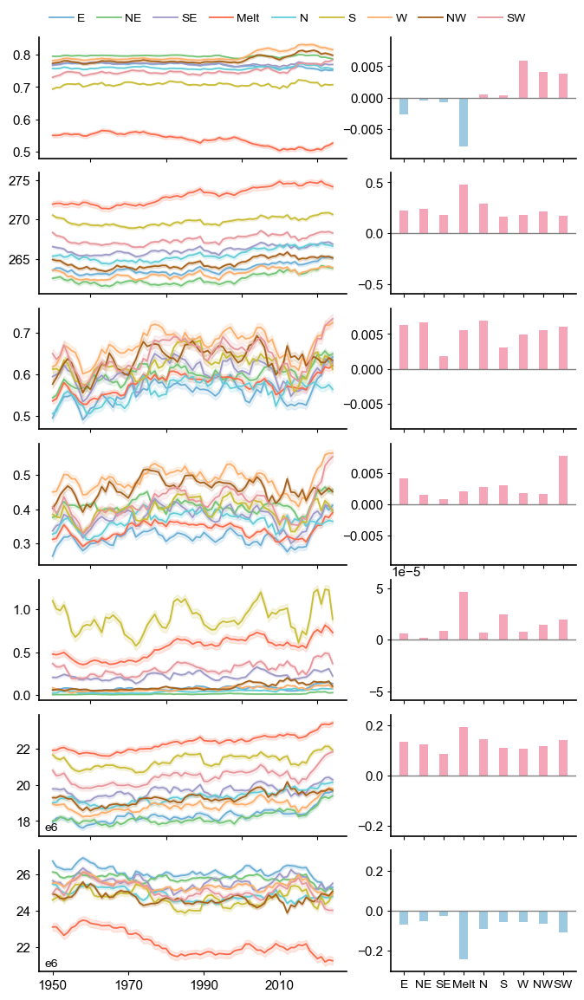

In [2]:
# -*- coding: utf-8 -*-
"""
NPJ-style Greenland Multi-Variable Time Series + Trend Panel (Refined v12)
→ 动态跳过CSV中不存在的变量，不留空白行。
→ 统一所有科学计数法标签 (如 'e6', 'e-5') 到子图左下角，并移除 '1'。
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import linregress

# ========= 参数 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_TimeseriesTrend_AllVar_v12_final.png" # 更新保存路径

# 理想的变量顺序和名称
VAR_DISPLAY_NAMES_ALL = {
    "albedo": "Albedo", "t2m": "T2m", "z500": "500 hPa Z",
    "z200": "200 hPa Z", "tcc": "Tcc", "lcc": "Lcc",
    "rf": "Rf", "strd": "Strd", "ssrd": "Ssrd"
}
desired_vars_ordered = list(VAR_DISPLAY_NAMES_ALL.keys()) 

region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Total']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Total':'#969696'
}

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

# ========= 数据处理 =========
df = pd.read_csv(CSV_PATH)
variable_mapping = {
    'alb': 'albedo', 'hc': 'hcc', 'lc': 'lcc', 'rf': 'rf', 'sf': 'sf',
    'ssrd': 'ssrd', 'strd': 'strd', 't2m': 't2m', 'tcc': 'tcc',
    'tp': 'tp', 'vimdf': 'vimdf'
}
df['Variable'] = df['Variable'].replace(variable_mapping)
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW','Total':'Total'
})

# **【修改 1】**： 动态确定要绘制的变量
# 1. 获取数据中实际存在的变量
present_vars_in_df = df['Variable'].unique()
# 2. 筛选出“想要的”且“存在的”变量，并保持顺序
variables_to_plot = [v for v in desired_vars_ordered if v in present_vars_in_df]

# 如果筛选后没有任何变量，则停止
if not variables_to_plot:
    print("CSV文件中未找到任何指定的变量，程序退出。")
    # 在脚本中运行时，使用 exit()
    # exit() 
    # 在Jupyter/IPython中，可以 raising an error
    raise SystemExit("CSV文件中未找到任何指定的变量，程序退出。")


def calc_trend(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    slope, _, _, p, _ = linregress(x[mask], y[mask])
    return slope * 10, p

# ========= 绘图 =========
# **【修改 1】**： n_var, figsize, 和 GridSpec 现在基于 *实际存在* 的变量
n_var = len(variables_to_plot)

fig = plt.figure(figsize=(8, n_var * 2.0)) 
gs = GridSpec(n_var, 2, width_ratios=[1.2, 0.72], wspace=0.18, hspace=0.12)
handles, labels = [], []


# 循环现在使用筛选后的 'variables_to_plot' 列表
for i, var in enumerate(variables_to_plot):
    sub = df[df['Variable'] == var].copy()
    
    if var in ['ssrd', 'strd']: 
        sub['Value'] = sub['Value'] / 1e6

    # ---- 折线图 ----
    ax1 = fig.add_subplot(gs[i, 0])
    for r in region_order:
        dat = sub[sub['Region'] == r].sort_values('Year')
        if dat.empty: 
            continue
        y = dat['Value'].rolling(5, center=True, min_periods=1).mean()
        line, = ax1.plot(dat['Year'], y, color=colors[r], lw=1.3)
        if i == 0:
            handles.append(line)
            labels.append(r)
        
        ax1.fill_between(dat['Year'], y - y.std()/3, y + y.std()/3,
                         color=colors[r], alpha=0.15)

    # ---- 轴样式 ----
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    if i < n_var - 1:
        ax1.set_xticklabels([])
    else:
        ax1.set_xticks(np.arange(1950, 2030, 20))
    ax1.tick_params(direction='out', length=3)

    # ---- 科学计数法 ----
    if var in ['ssrd', 'strd']: 
        ax1.ticklabel_format(axis='y', style='plain')
    else:
        # 启用自动科学计数法，以便获取 'offset_text'
        ax1.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))


    # **【修改 2】**： 统一所有科学计数法标签位置
    # 1. 获取自动生成的 offset_text 对象
    offset_text = ax1.yaxis.get_offset_text()
    original_text = offset_text.get_text()
    
    # 2. 隐藏 Matplotlib 自动放置的（混乱的）文本
    offset_text.set_visible(False)

    # 3. 定义统一的放置位置：左下角
    x_pos = 0.02 # 靠近左侧
    y_pos = 0.02 # 靠近底部
    text_kwargs = {
        'transform': ax1.transAxes,
        'fontsize': 10, 
        'color': 'black',
        'ha': 'left', 
        'va': 'bottom'
    }

    # 4. 手动在统一位置绘制标签
    if var in ['ssrd', 'strd']:
        # 4a. 手动情况：只写 'e6'
        ax1.text(x_pos, y_pos, "e6", **text_kwargs)
        
    elif original_text: # 4b. 自动情况
        # 格式化文本 (去掉 '1')
        
        # 匹配 Matplotlib 的 LaTeX 格式 (正数): $10^{X}$ -> $e^{X}$
        text = original_text.replace(r'10^{', r'e^{') 
        
        # 匹配 Matplotlib 的 LaTeX 格式 (负数): $10^{-X}$ -> $e^{-X}$
        text = text.replace(r'10^{-', r'e^{-')
        
        # 匹配非 LaTeX 格式： 1eX -> eX (例如 1e-5 -> e-5)
        text = text.replace('1e', 'e')
        
        # 在新位置绘制
        ax1.text(x_pos, y_pos, text, **text_kwargs)


    # ---- 柱状趋势 ----
    ax2 = fig.add_subplot(gs[i, 1])
    trends, pvals = [], []
    for r in region_order:
        dat = sub[sub['Region'] == r]
        if dat.empty:
            trends.append(np.nan); pvals.append(np.nan); continue
        slope, p = calc_trend(dat['Year'].values, dat['Value'].values)
        trends.append(slope); pvals.append(p)

    cols = ['#f4a6b8' if t > 0 else '#9ecae1' for t in trends]
    ax2.bar(region_order, trends, color=cols, width=0.45)
    ax2.axhline(0, color='gray', lw=1)
    if np.isfinite(trends).any():
        lim = np.nanmax(np.abs(trends)) * 1.25
        ax2.set_ylim(-lim, lim)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.tick_params(direction='out', length=3)
    if i < n_var - 1:
        ax2.set_xticklabels([])
    else:
        ax2.set_xticklabels(region_order, fontsize=10, rotation=0) 
        ax2.set_xlabel("")
    ax2.set_title("") 

# **【图例修正】** 图例一行 (ncol=10)，紧贴，缩小间距
# 仅在至少有一个图例条目时才显示
if handles and labels:
    ax1_first = fig.axes[0] 
    ax1_first.legend(handles, labels, 
                     ncol=10, 
                     loc='lower left', 
                     bbox_to_anchor=(0, 1.02), 
                     fontsize=10, frameon=False, 
                     columnspacing=1.0, 
                     handletextpad=0.3)


# ---- 稳定布局 ----
fig.set_constrained_layout(True) 

plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

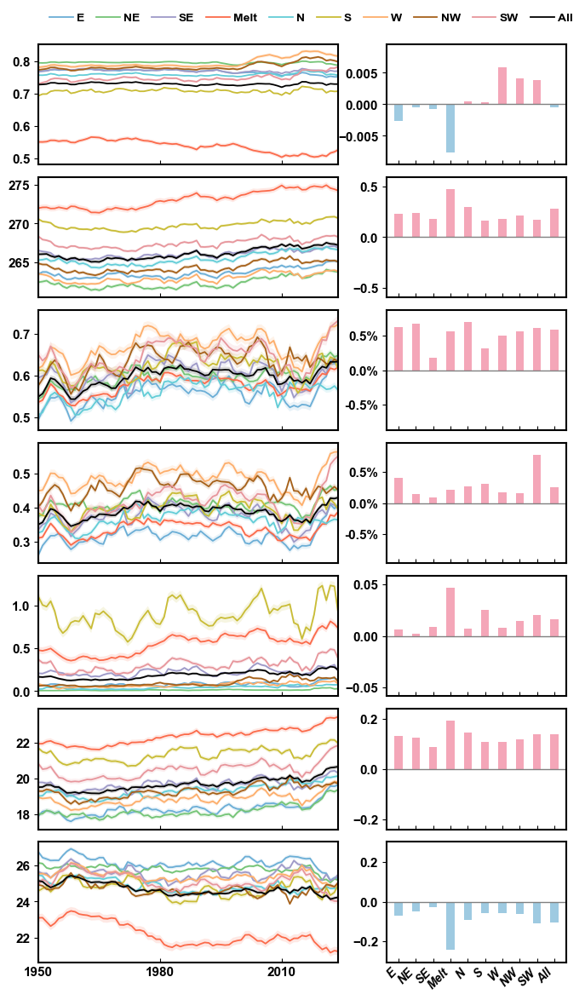

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
from scipy.stats import linregress

# ========= 参数 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_TimeseriesTrend_Final_v17_Bold.png"

VAR_DISPLAY_NAMES_ALL = {
    "albedo": "Albedo", "t2m": "T2m", "z500": "500 hPa Z",
    "z200": "200 hPa Z", "tcc": "Tcc", "lcc": "Lcc",
    "rf": "Rf", "strd": "Strd", "ssrd": "Ssrd"
}
desired_vars_ordered = list(VAR_DISPLAY_NAMES_ALL.keys()) 

region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Entire']
region_display = ['E','NE','SE','Melt','N','S','W','NW','SW','All']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Entire':'#000000'
}

# ========= 样式全局加粗 =========
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'      # 全局字体加粗
plt.rcParams['axes.labelweight'] = 'bold' # 轴标签加粗
plt.rcParams['axes.linewidth'] = 1.5      # 边框稍微加粗以匹配黑体字
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'out'

# ========= 数据处理 =========
df = pd.read_csv(CSV_PATH)
variable_mapping = {
    'alb': 'albedo', 'hc': 'hcc', 'lc': 'lcc', 'rf': 'rf', 'sf': 'sf',
    'ssrd': 'ssrd', 'strd': 'strd', 't2m': 't2m', 'tcc': 'tcc',
    'tp': 'tp', 'vimdf': 'vimdf'
}
df['Variable'] = df['Variable'].replace(variable_mapping)
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW',
    'The Entire Greenland Area':'Entire'
})

present_vars_in_df = df['Variable'].unique()
variables_to_plot = [v for v in desired_vars_ordered if v in present_vars_in_df]

if not variables_to_plot:
    raise SystemExit("CSV文件中未找到任何指定的变量，程序退出。")

def calc_trend(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    slope, _, _, p, _ = linregress(x[mask], y[mask])
    return slope * 10, p 

# ========= 绘图 =========
n_var = len(variables_to_plot)
fig = plt.figure(figsize=(8, n_var * 2.0)) 

# wspace=0.08: 紧贴布局
gs = GridSpec(n_var, 2, width_ratios=[1.2, 0.72], wspace=0.20, hspace=0.1)

handles, labels = [], []
year_min = df['Year'].min()
year_max = df['Year'].max()

for i, var in enumerate(variables_to_plot):
    sub = df[df['Variable'] == var].copy()
    
    # SSRD/STRD 除以 1e6
    if var in ['ssrd', 'strd']: 
        sub['Value'] = sub['Value'] / 1e6
    
    # RF 乘以 1000
    if var == 'rf':
        sub['Value'] = sub['Value'] * 1000

    # -----------------------
    # Left: Time Series
    # -----------------------
    ax1 = fig.add_subplot(gs[i, 0])
    
    for r in region_order:
        dat = sub[sub['Region'] == r].sort_values('Year')
        if dat.empty: continue
        
        y = dat['Value'].rolling(5, center=True, min_periods=1).mean()
        line, = ax1.plot(dat['Year'], y, color=colors[r], lw=1.3)
        
        if i == 0:
            handles.append(line)
            labels.append('All' if r == 'Entire' else r)
        
        ax1.fill_between(dat['Year'], y - y.std()/3, y + y.std()/3,
                         color=colors[r], alpha=0.15, edgecolor='none')

    ax1.set_xlim(year_min, year_max)
    ax1.ticklabel_format(axis='y', style='sci', scilimits=(-3, 4))
    ax1.yaxis.get_offset_text().set_visible(False)
    
    # 强制刻度字体加粗 (虽然rcParams已设置，但显式刷新更稳妥)
    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_fontweight('bold')

    if i < n_var - 1:
        ax1.set_xticklabels([])
        ax1.set_xticks([1950, 1980, 2010])
    else:
        ax1.set_xticks([1950, 1980, 2010])
        ax1.set_xticklabels(['1950', '1980', '2010'])

    # -----------------------
    # Right: Bar Trend
    # -----------------------
    ax2 = fig.add_subplot(gs[i, 1])
    trends, pvals = [], []
    
    for r in region_order:
        dat = sub[sub['Region'] == r]
        if dat.empty:
            trends.append(np.nan); continue
        slope, p = calc_trend(dat['Year'].values, dat['Value'].values)
        trends.append(slope)

    cols = ['#f4a6b8' if t > 0 else '#9ecae1' for t in trends]
    ax2.bar(region_display, trends, color=cols, width=0.45, edgecolor='none')
    ax2.axhline(0, color='gray', lw=1)
    
    if np.isfinite(trends).any():
        lim = np.nanmax(np.abs(trends)) * 1.25
        if lim == 0: lim = 0.1
        ax2.set_ylim(-lim, lim)

    # Tcc / Lcc 显示为百分比 (加粗)
    if var in ['tcc', 'lcc']:
        ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: '{:.1f}%'.format(x*100)))
    else:
        ax2.ticklabel_format(axis='y', style='plain') 

    # 刻度字体加粗
    for label in ax2.get_yticklabels():
        label.set_fontweight('bold')

    if i < n_var - 1:
        ax2.set_xticklabels([])
    else:
        ax2.set_xticks(range(len(region_display)))
        # 45度旋转 + 加粗 + 斜体
        ax2.set_xticklabels(region_display, fontsize=10, rotation=45, ha='right',
                            fontweight='bold', fontstyle='italic')
        ax2.set_xlabel("")

# Legend
if handles and labels:
    ax1_first = fig.axes[0]
    ax1_first.legend(handles, labels, 
                     ncol=10, 
                     loc='lower left', 
                     bbox_to_anchor=(0, 1.08), 
                     fontsize=10, frameon=False, 
                     columnspacing=1.0, 
                     handletextpad=0.3,
                     prop={'weight': 'bold'}) # 图例字体加粗

plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

In [1]:
#===================================拉伸和拼接图象==========================================
from PIL import Image
import os

def stitch_images_horizontal(img_path1, img_path2, output_path):
    """
    水平拼接两个图像，并将较矮的图像拉伸以匹配较高图像的高度。
    """
    try:
        # 打开图像并确保它们支持透明度 (RGBA)
        img1 = Image.open(img_path1).convert("RGBA")
        img2 = Image.open(img_path2).convert("RGBA")

        # 获取图像尺寸
        width1, height1 = img1.size
        width2, height2 = img2.size

        # 确定目标高度（取两者中较高的）
        target_height = max(height1, height2)

        # --- 调整图像大小以匹配目标高度 ---
        # 如果图像1不是目标高度，拉伸它
        if height1 != target_height:
            # 计算新的宽度以保持原始宽高比
            new_width1 = int(width1 * (target_height / height1))
            print(f"正在将 {os.path.basename(img_path1)} 的高度从 {height1} 拉伸到 {target_height}...")
            img1 = img1.resize((new_width1, target_height), Image.LANCZOS)
            width1, height1 = img1.size # 更新尺寸

        # 如果图像2不是目标高度，拉伸它
        if height2 != target_height:
            # 计算新的宽度以保持原始宽高比
            new_width2 = int(width2 * (target_height / height2))
            print(f"正在将 {os.path.basename(img_path2)} 的高度从 {height2} 拉伸到 {target_height}...")
            img2 = img2.resize((new_width2, target_height), Image.LANCZOS)
            width2, height2 = img2.size # 更新尺寸

        # 创建新的空白图像
        total_width = width1 + width2
        new_img = Image.new('RGBA', (total_width, target_height), (0, 0, 0, 0)) # 透明背景

        # 将两图像粘贴到新图像上
        new_img.paste(img1, (0, 0))
        new_img.paste(img2, (width1, 0)) # 粘贴在第一个图像的右侧

        # 保存结果
        new_img.save(output_path)
        print(f"\n成功！图像已拼接并保存到: {output_path}")

    except FileNotFoundError as e:
        print(f"错误：找不到文件 {e.filename}。请检查路径是否正确。")
    except Exception as e:
        print(f"发生错误: {e}")

# --- 你的文件路径 ---

# 请注意：Python中的路径需要使用正斜杠 (/) 或双反斜杠 (\\)
left_image_path = r"C:\greenland\1995bu\fig4\left.png"
right_image_path = r"C:\greenland\1995bu\fig4\right.png"

# 定义你希望保存的输出文件路径
output_image_path = r"C:\greenland\1995bu\fig4\stitched_figure.png"

# 执行拼接
stitch_images_horizontal(left_image_path, right_image_path, output_image_path)

正在将 right.png 的高度从 4694 拉伸到 6691...

成功！图像已拼接并保存到: C:\greenland\1995bu\fig4\stitched_figure.png


In [ ]:
from PIL import Image

def stitch_images_horizontal(img_path1, img_path2, output_path):
    img1 = Image.open(img_path1).convert("RGBA")
    img2 = Image.open(img_path2).convert("RGBA")

    # 获取图像尺寸
    width1, height1 = img1.size
    width2, height2 = img2.size

    # 确定目标高度（取两者中较高的）
    target_height = max(height1, height2)

    # 如果需要拉伸，则调整图像大小
    if height1 != target_height:
        # 计算新的宽度以保持宽高比，如果不是等比例拉伸，则直接设置高度并让宽度变化
        # 为了拉伸到目标高度并保持对齐，我们直接设置高度，宽度会随之改变
        img1 = img1.resize((int(width1 * (target_height / height1)), target_height), Image.LANCZOS)
        width1, height1 = img1.size # 更新尺寸

    if height2 != target_height:
        img2 = img2.resize((int(width2 * (target_height / height2)), target_height), Image.LANCZOS)
        width2, height2 = img2.size # 更新尺寸

    # 创建新的空白图像，宽度为两图像宽度之和，高度为目标高度
    total_width = width1 + width2
    new_img = Image.new('RGBA', (total_width, target_height))

    # 将两图像粘贴到新图像上
    new_img.paste(img1, (0, 0))
    new_img.paste(img2, (width1, 0)) # 第二个图像从第一个图像的宽度之后开始粘贴

    new_img.save(output_path)
    print(f"图像已拼接并保存到: {output_path}")

# 示例用法
# stitch_images_horizontal("image1.png", "image2.png", "stitched_image.png")

# 如果你想垂直拼接
def stitch_images_vertical(img_path1, img_path2, output_path):
    img1 = Image.open(img_path1).convert("RGBA")
    img2 = Image.open(img_path2).convert("RGBA")

    width1, height1 = img1.size
    width2, height2 = img2.size

    target_width = max(width1, width2)

    if width1 != target_width:
        img1 = img1.resize((target_width, int(height1 * (target_width / width1))), Image.LANCZOS)
        width1, height1 = img1.size

    if width2 != target_width:
        img2 = img2.resize((target_width, int(height2 * (target_width / width2))), Image.LANCZOS)
        width2, height2 = img2.size

    total_height = height1 + height2
    new_img = Image.new('RGBA', (target_width, total_height))

    new_img.paste(img1, (0, 0))
    new_img.paste(img2, (0, height1))

    new_img.save(output_path)
    print(f"图像已垂直拼接并保存到: {output_path}")

# 这是一个使用示例：
# 创建两个示例图片
# Image.new('RGBA', (300, 200), (255, 0, 0, 255)).save("red_rect.png")
# Image.new('RGBA', (400, 250), (0, 0, 255, 255)).save("blue_rect.png")
# stitch_images_horizontal("red_rect.png", "blue_rect.png", "stitched_horizontal.png")
# stitch_images_vertical("red_rect.png", "blue_rect.png", "stitched_vertical.png")

In [2]:
# -*- coding: utf-8 -*-
"""
Greenland Basin Time Series Generator (Summer Mean)
---------------------------------------------------
• 支持变量: RF, TCC, T2M, STRD, SSRD
• 自动识别 valid_time / time
• 提取夏季 (JJA, 6–8月) 平均 → 年度序列
• STRD, SSRD 自动单位缩放为 MJ m⁻²
• 输出 CSV + PNG (9 Basins + Whole Greenland)
"""

import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# =============== 基本路径 ===============
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
OUT_DIR   = r"C:\greenland\1995bu"
os.makedirs(OUT_DIR, exist_ok=True)

# =============== 变量任务列表 ===============
VAR_TASKS = [
    dict(name="RF",    nc=r"C:\greenland\sf_tp_rf.nc", 
         var="rf",   ylabel="Rainfall (m water eq)"),
    dict(name="TCC",   nc=r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc", 
         var="tcc",  ylabel="Total Cloud Cover (0–1)"),
    dict(name="T2M",   nc=r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc", 
         var="t2m",  ylabel="2 m Temperature (K)"),
    dict(name="STRD",  nc=r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc", 
         var="strd", ylabel="Downwelling Longwave (MJ m⁻²)"),
    dict(name="SSRD",  nc=r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc", 
         var="ssrd", ylabel="Downwelling Shortwave (MJ m⁻²)"),
]

# =============== 区域缩写映射 ===============
NAME_MAP = {
    "East": "E", "EastNorth": "NE", "EastSouth": "SE",
    "Melt": "Melt", "North": "N", "South": "S",
    "West": "W", "WestNorth": "NW", "WestSouth": "SW",
    "The Entire Greenland Area": "The Entire Greenland Area"
}

# =============== Matplotlib风格 ===============
FONT = 15
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT,
    "axes.linewidth": 1.0,
    "axes.edgecolor": "0.3",
    "xtick.direction": "out",
    "ytick.direction": "out"
})

# ---------------------------------------------------------------------
# 基础函数
# ---------------------------------------------------------------------
def _ensure_crs(da):
    """写入EPSG:4326 CRS"""
    if not da.rio.crs:
        da.rio.write_crs("EPSG:4326", inplace=True)
    return da

def _read_regions():
    """读取9个流域 + 全格陵兰 shapefile"""
    regions = []
    for shp in sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp"))):
        g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
        name = os.path.splitext(os.path.basename(shp))[0]
        regions.append((name, g))
    full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
    regions.append(("The Entire Greenland Area", full))
    return regions

def _trend_per_decade(years, values):
    ok = np.isfinite(values) & np.isfinite(years)
    if ok.sum() < 2: return np.nan
    return np.polyfit(years[ok], values[ok], 1)[0] * 10

# ---------------------------------------------------------------------
# 主计算函数
# ---------------------------------------------------------------------
def compute_basin_series(ncpath, var):
    """读取 NetCDF, 提取 JJA 年度均值, 计算 basin 序列"""
    if not os.path.exists(ncpath):
        print(f"❌ 未找到文件: {ncpath}")
        return pd.DataFrame()

    ds = xr.open_dataset(ncpath)
    # 自动识别时间维
    if "valid_time" in ds:
        ds = ds.rename({"valid_time": "time"})
    if "latitude" in ds:
        ds = ds.rename({"latitude": "lat"})
    if "longitude" in ds:
        ds = ds.rename({"longitude": "lon"})
    da = ds[var].squeeze(drop=True)
    da = _ensure_crs(da)

    # ---- 单位缩放 ----
    if var in ["strd", "ssrd"]:
        da = da / 1e6
        da.attrs["units"] = "MJ m⁻²"

    # ---- 夏季 (JJA) 平均到年度 ----
    if np.issubdtype(da["time"].dtype, np.datetime64):
        da = da.sel(time=da["time"].dt.month.isin([6, 7, 8]))
        da = da.groupby("time.year").mean("time", skipna=True)
        da = da.rename({"year": "time"})

    # ---- 区域均值 ----
    regions = _read_regions()
    recs = []
    for name, g in regions:
        print(f"→ {os.path.basename(ncpath)} | {name}")
        try:
            clip = da.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
            ts = clip.mean(dim=("lat", "lon"), skipna=True).to_pandas()
            recs.append(pd.DataFrame({
                "Year": ts.index.astype(int),
                "Value": ts.values,
                "Region": name
            }))
        except Exception as e:
            print(f"   ⚠️ 裁剪失败 {name}: {e}")

    if not recs:
        return pd.DataFrame()

    df = pd.concat(recs, ignore_index=True)
    df = df.sort_values(["Region", "Year"])
    df["mean_5yr"] = df.groupby("Region")["Value"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
    df["std_5yr"]  = df.groupby("Region")["Value"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
    df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(
        lambda g: pd.Series(_trend_per_decade(g["Year"], g["Value"]), index=g.index)
    )
    df["units"] = da.attrs.get("units", "")
    return df

# ---------------------------------------------------------------------
# 绘图函数
# ---------------------------------------------------------------------
def plot_basin_series(df, ylabel, outpng):
    if df.empty:
        print(f"⚠️ 数据为空，跳过绘图: {outpng}")
        return
    fig, ax = plt.subplots(figsize=(12,6), dpi=300)

    regions = [r for r in df["Region"].unique() if r != "The Entire Greenland Area"]
    regions.append("The Entire Greenland Area")
    colors = plt.cm.tab10(np.linspace(0,1,len(regions)-1))

    # 9 Basins
    for (name, col) in zip(regions[:-1], colors):
        sub = df[df["Region"]==name]
        label = f"{NAME_MAP.get(name,name)} ({sub['trend_per_decade'].iloc[0]:+.3g}/dec)"
        ax.plot(sub["Year"], sub["mean_5yr"], lw=1.4, color=col, label=label)
        ax.fill_between(sub["Year"],
                        sub["mean_5yr"]-sub["std_5yr"],
                        sub["mean_5yr"]+sub["std_5yr"],
                        color=col, alpha=0.18)
    # Greenland
    all_df = df[df["Region"]=="The Entire Greenland Area"]
    label_all = f"{NAME_MAP['The Entire Greenland Area']} ({all_df['trend_per_decade'].iloc[0]:+.3g}/dec)"
    ax.plot(all_df["Year"], all_df["mean_5yr"], lw=2.0, color="k", alpha=0.8, label=label_all)
    ax.fill_between(all_df["Year"],
                    all_df["mean_5yr"]-all_df["std_5yr"],
                    all_df["mean_5yr"]+all_df["std_5yr"],
                    color="gray", alpha=0.12)

    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xlim(df["Year"].min(), df["Year"].max())
    ax.set_xticks(np.arange(df["Year"].min(), df["Year"].max()+1, 5))
    ax.grid(alpha=0.15, linewidth=0.4)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5,1.01), frameon=False)

    fig.tight_layout(rect=[0,0,1,0.98])
    fig.savefig(outpng, dpi=300, bbox_inches="tight")
    print(f"✅ Figure saved: {outpng}")
    plt.close(fig)

# ---------------------------------------------------------------------
# 主流程
# ---------------------------------------------------------------------
for t in VAR_TASKS:
    print(f"\n================ {t['name']} ================")
    df = compute_basin_series(t["nc"], t["var"])
    if df.empty: 
        continue
    outcsv = os.path.join(OUT_DIR, f"Fig_Greenland_9Basin_{t['name']}_TimeSeries.csv")
    outpng = os.path.join(OUT_DIR, f"Fig_Greenland_9Basin_{t['name']}_TimeSeries.png")
    df.to_csv(outcsv, index=False)
    print(f"✅ Data saved: {outcsv}")
    plot_basin_series(df, t["ylabel"], outpng)



================ RF ================
→ sf_tp_rf.nc | East
→ sf_tp_rf.nc | EastNorth
→ sf_tp_rf.nc | EastSouth
→ sf_tp_rf.nc | Melt
→ sf_tp_rf.nc | North
→ sf_tp_rf.nc | South
→ sf_tp_rf.nc | West
→ sf_tp_rf.nc | WestNorth
→ sf_tp_rf.nc | WestSouth
→ sf_tp_rf.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_RF_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_RF_TimeSeries.png

================ TCC ================
→ greenland_tcc_full.nc | East
→ greenland_tcc_full.nc | EastNorth
→ greenland_tcc_full.nc | EastSouth
→ greenland_tcc_full.nc | Melt
→ greenland_tcc_full.nc | North
→ greenland_tcc_full.nc | South
→ greenland_tcc_full.nc | West
→ greenland_tcc_full.nc | WestNorth
→ greenland_tcc_full.nc | WestSouth
→ greenland_tcc_full.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_TCC_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_TCC_TimeSeries.png

================ T2M ================
→ ERA5LANDfeature_greenland.nc | East
→ ERA5LANDfeature_greenland.nc | EastNorth
→ ERA5LANDfeature_greenland.nc | EastSouth
→ ERA5LANDfeature_greenland.nc | Melt
→ ERA5LANDfeature_greenland.nc | North
→ ERA5LANDfeature_greenland.nc | South
→ ERA5LANDfeature_greenland.nc | West
→ ERA5LANDfeature_greenland.nc | WestNorth
→ ERA5LANDfeature_greenland.nc | WestSouth
→ ERA5LANDfeature_greenland.nc | The Entire Greenland Area


...

✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_T2M_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_T2M_TimeSeries.png

================ STRD ================
→ ERA5LANDfeature_greenland.nc | East
→ ERA5LANDfeature_greenland.nc | EastNorth
→ ERA5LANDfeature_greenland.nc | EastSouth
→ ERA5LANDfeature_greenland.nc | Melt
→ ERA5LANDfeature_greenland.nc | North
→ ERA5LANDfeature_greenland.nc | South
→ ERA5LANDfeature_greenland.nc | West
→ ERA5LANDfeature_greenland.nc | WestNorth
→ ERA5LANDfeature_greenland.nc | WestSouth
→ ERA5LANDfeature_greenland.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:183: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.tight_layout(rect=[0,0,1,0.98])
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:184: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.savefig(outpng, dpi=300, bbox_inches="tight")


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_STRD_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_STRD_TimeSeries.png

================ SSRD ================
→ ERA5LANDfeature_greenland.nc | East
→ ERA5LANDfeature_greenland.nc | EastNorth
→ ERA5LANDfeature_greenland.nc | EastSouth
→ ERA5LANDfeature_greenland.nc | Melt
→ ERA5LANDfeature_greenland.nc | North
→ ERA5LANDfeature_greenland.nc | South
→ ERA5LANDfeature_greenland.nc | West
→ ERA5LANDfeature_greenland.nc | WestNorth
→ ERA5LANDfeature_greenland.nc | WestSouth
→ ERA5LANDfeature_greenland.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:183: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.tight_layout(rect=[0,0,1,0.98])
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:184: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.savefig(outpng, dpi=300, bbox_inches="tight")


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_SSRD_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_SSRD_TimeSeries.png


Calculating region: East
Calculating region: EastNorth
Calculating region: EastSouth
Calculating region: Melt
Calculating region: North
Calculating region: South
Calculating region: West
Calculating region: WestNorth
Calculating region: WestSouth
Calculating region: The Entire Greenland Area
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.png


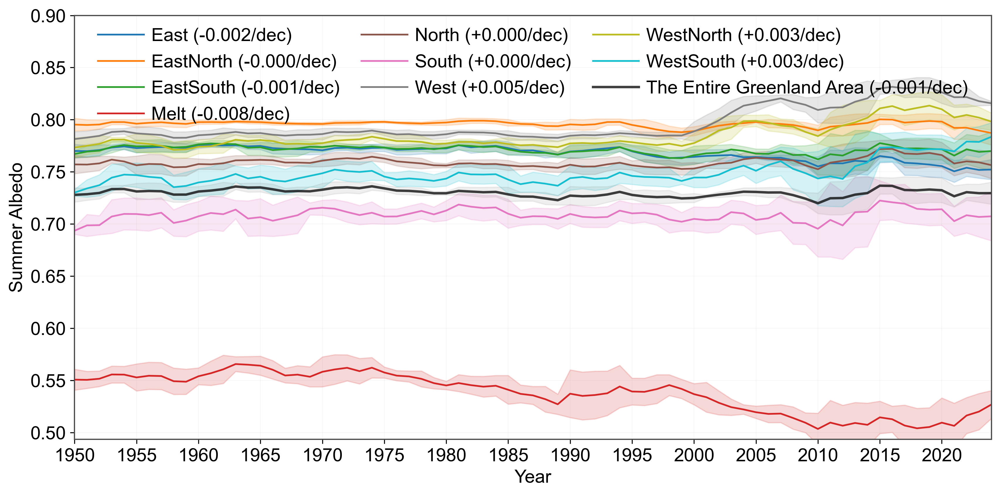

In [ ]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 =========
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
NC_PATH   = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR   = r"C:\greenland\1995bu"
OUT_CSV   = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.csv")
OUT_FIG   = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.png")

# ========= 读取数据 =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取9个分区 + 全格陵兰 =========
regions = []
if albedo is not None:
    basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
    try:
        for shp in basin_shps:
            g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
            name = os.path.splitext(os.path.basename(shp))[0]
            regions.append((name, g))
        full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
        regions.append(("The Entire Greenland Area", full))
    except Exception as e:
        print(f"错误：读取Shapefile失败：{e}")

# ========= 计算时间序列 =========
records = []
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        years = ds["time"].values if not np.issubdtype(ts.index.dtype, np.datetime64) else pd.to_datetime(ts.index).year
        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region", "Year"])
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"]  = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        df = None
else:
    print("❌ 未能成功加载区域或反照率数据")
    df = None

# *************************************************************************
# ************************* START OF USER CUSTOMIZATION BLOCK ***************
# *************************************************************************
LEGEND_Y_OFFSET = 1.01 
# *************************************************************************
# ************************* END OF USER CUSTOMIZATION BLOCK ****************
# *************************************************************************

# ======== 新增：附加每个流域趋势 ========
trend_data = {
    "East": -0.002329151,
    "EastNorth": -0.000280762,
    "EastSouth": -0.000768503,
    "Melt": -0.00770941,
    "North": 0.000276715,
    "South": 0.000362804,
    "West": 0.004832396,
    "WestNorth": 0.003325931,
    "WestSouth": 0.003440071,
    "The Entire Greenland Area": -0.000666594
}

# ========= 绘图 =========
if df is not None:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
    if regions:
        num_basins = len(regions) - 1
        colors = plt.cm.tab10(np.linspace(0,1,num_basins))

        # 绘制9个分区
        for (name, _), col in zip(regions[:-1], colors):
            grp = df[df["Region"] == name]
            label = f"{name} ({trend_data.get(name, np.nan):+.3f}/dec)"  # 加上趋势值
            ax.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4, label=label)
            ax.fill_between(grp["Year"],
                            grp["mean_5yr"] - grp["std_5yr"],
                            grp["mean_5yr"] + grp["std_5yr"],
                            color=col, alpha=0.18)

        # 绘制全格陵兰
        gall = df[df["Region"] == "The Entire Greenland Area"]
        gall_label = f"The Entire Greenland Area ({trend_data['The Entire Greenland Area']:+.3f}/dec)"
        ax.plot(gall["Year"], gall["mean_5yr"], color="k", lw=2.0, alpha=0.75, label=gall_label)
        ax.fill_between(gall["Year"],
                        gall["mean_5yr"] - gall["std_5yr"],
                        gall["mean_5yr"] + gall["std_5yr"],
                        color="gray", alpha=0.12)

    # ======== 图形美化 ========
    ax.set_xlabel("Year", fontsize=15)
    ax.set_ylabel("Summer Albedo", fontsize=15)
    ax.set_xlim(1950, 2024)
    ax.set_xticks(np.arange(1950, 2025, 5))
    min_albedo = df["mean_5yr"].min() if not df.empty else 0.5
    ax.set_ylim(min_albedo - 0.01, 0.9)
    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
        ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
    ax.grid(alpha=0.15, linewidth=0.4)

    # ======== 图例改为3行 ========
    ax.legend(
        frameon=False, fontsize=15, ncol=3, loc="upper center",
        bbox_to_anchor=(0.5, LEGEND_Y_OFFSET),
        handlelength=2.5, handletextpad=0.4, columnspacing=1.2
    )

    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成。")
    #"C:\greenland\1995bu\Fig_Greenland_9Basin_TrendStats.csv"--------------用的趋势是这里的数据


Calculating region: <1500m
Calculating region: 1500-2000m
Calculating region: 2000-2500m
Calculating region: 2500-3000m
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_IsoContour_AlbedoTimeSeries.csv


C:\Users\11823\AppData\Local\Temp\ipykernel_13508\3218693409.py:109: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', num_contoured_regions)


✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_IsoContour_AlbedoTimeSeries.png


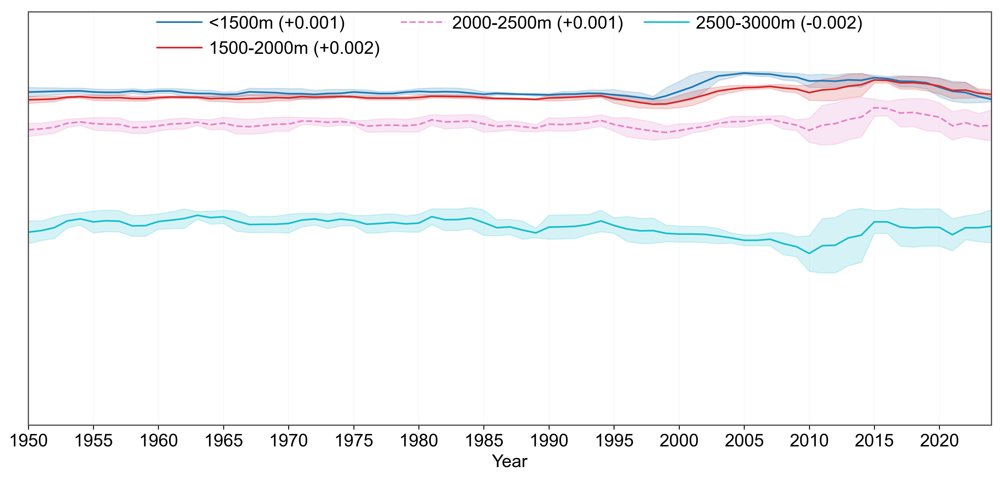

In [71]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 =========
ISO_CONTOUR_SHP = r"C:\greenland\Greenland_shp\等间距等值线.shp"
NC_PATH   = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR   = r"C:\greenland\1995bu"
OUT_CSV   = os.path.join(OUT_DIR, "Fig_Greenland_IsoContour_AlbedoTimeSeries.csv")
OUT_FIG   = os.path.join(OUT_DIR, "Fig_Greenland_IsoContour_AlbedoTimeSeries.png")

# ========= 读取数据 =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}。")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取等值线分区 =========
regions = []
CUSTOM_REGION_NAMES = ['<1500m', '1500-2000m', '2000-2500m', '2500-3000m', '>3000m'] 

if albedo is not None:
    try:
        iso_gdf = gpd.read_file(ISO_CONTOUR_SHP).to_crs("EPSG:4326")
        for index, row in iso_gdf.head(len(CUSTOM_REGION_NAMES)).iterrows(): 
            name = CUSTOM_REGION_NAMES[index]
            g = gpd.GeoDataFrame([row], crs=iso_gdf.crs).dissolve().reset_index(drop=True)
            regions.append((name, g))
    except Exception as e:
        print(f"错误：读取等值线Shapefile失败：{e}")

# ========= 计算时间序列 =========
records = []
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        
        if not np.issubdtype(ts.index.dtype, np.datetime64):
            years = ds["time"].values
        else:
            years = pd.to_datetime(ts.index).year

        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region","Year"])
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"]  = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        df = None
        print("❌ 未能成功计算时间序列。")
else:
    print("❌ 未能成功加载区域或反照率数据，跳过时间序列计算和绘图。")
    df = None

# ========= 用户自定义 =========
LEGEND_Y_OFFSET = 1.03  # 图例垂直偏移量

# ======== 附加趋势信息 ========
trend_data = {
    "<1500m": 0.001483404,
    "1500-2000m": 0.001641699,
    "2000-2500m": 0.000724387,
    "2500-3000m": -0.00201562,
    ">3000m": np.nan
}
p_value_data = {
    "<1500m": 0.000193103,
    "1500-2000m": 5.53E-07,
    "2000-2500m": 0.12176295,
    "2500-3000m": 0.003052131,
    ">3000m": np.nan
}

# ========= 绘图 =========
if df is not None and not df.empty:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

    plotting_order = CUSTOM_REGION_NAMES
    unique_regions = [r for r in plotting_order if r in df["Region"].unique()]
    num_contoured_regions = len(unique_regions)
    colors = plt.cm.get_cmap('tab10', num_contoured_regions)

    for i, name in enumerate(unique_regions):
        col = colors(i)
        grp = df[df["Region"] == name]

        slope = trend_data.get(name, np.nan)
        pval  = p_value_data.get(name, np.nan)

        # ==== 显著性控制 ====
        if np.isnan(pval) or pval >= 0.05:
            linestyle = "--"      # 不显著 → 虚线
            alpha = 0.9
        else:
            linestyle = "-"       # 显著 → 实线
            alpha = 1.0

        label = f"{name} ({slope:+.3f})"
        ax.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4, ls=linestyle, alpha=alpha, label=label)
        ax.fill_between(grp["Year"],
                        grp["mean_5yr"] - grp["std_5yr"],
                        grp["mean_5yr"] + grp["std_5yr"],
                        color=col, alpha=0.18)

    # ======== 图形美化 ========
    ax.set_xlabel("Year", fontsize=15)
    ax.set_yticks([])
    ax.set_yticklabels([])

    ax.set_xlim(1950, 2024)
    ax.set_xticks(np.arange(1950, 2025, 5))
    ax.set_ylim(0.50, 0.90)

    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
        ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
    ax.grid(alpha=0.15, linewidth=0.4)

    # ======== 图例 (3行, 15号字体, 居中) ========
    ax.legend(frameon=False, fontsize=15, ncol=3, loc="upper center",
              bbox_to_anchor=(0.5, LEGEND_Y_OFFSET),
              handlelength=2.5, handletextpad=0.4, columnspacing=1.2)

    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成或为空。")
